# Projeto de Machine Learning 2
## Previsão de vendas da drogaria Rossmann

**Equipe:** Bruno Pagani Rampinelli, João Henrique Camilo Fogaça e Vinícius dos Santos Nascimento

**Pergunta:** quais fatores influenciam a quantidade de vendas da Rossmann?

**Objetivo:** prever as vendas diárias de cada loja a partir das vendas passadas, levando em conta período do ano, feriados, promoções, entre outros.

### Problema de negócio

Segundo a descrição da competição no Kaggle, a Rossmann tem mais de 3.000 drogarias em 7 países da Europa (esta base traz 1.115 delas). Os gerentes das lojas precisam prever as vendas diárias com até seis semanas de antecedência, e cada um faz isso do seu jeito, com qualidade muito variável. Essa previsão orienta decisões do dia a dia: quantos funcionários escalar, quanto estoque pedir e onde vale a pena fazer promoção.

O projeto responde a três perguntas, cada uma com uma técnica e uma decisão:

| Pergunta do negócio | Técnica | Decisão que apoia | Seções |
|---|---|---|---|
| Quanto cada loja vai vender em cada dia? | Regressão supervisionada (Árvore, Random Forest, Gradient Boosting, SVR) | Escala de funcionários e pedido de estoque | 13 a 17 |
| O que faz a venda subir ou cair? | EDA, ablação, importância das variáveis e regras da árvore | Quando programar promoções e preparar vésperas de feriado | 8 e 16 |
| Que tipos de loja existem, e o que fazer em cada um? | Agrupamento não supervisionado (K-means) | Onde concentrar promoções e como ajustar equipe e sortimento por perfil | 12 |

| Item | Definição |
|---|---|
| Base | Rossmann Store Sales (Kaggle): `train.csv` e `store.csv` |
| Unidade de análise | Um dia de uma loja aberta (loja-dia) |
| Alvo (Y) | `Sales`, o faturamento da loja no dia |
| Tarefa | Regressão (supervisionada) + agrupamento das lojas com K-means (não supervisionado) |
| Modelos | Árvore de Decisão, Random Forest, Gradient Boosting, SVR e K-means |
| Métricas | MAE, RMSE e R² (as da aula de SVR) e RMSPE (métrica da competição) |
| Divisão | Treino 2013–2014, validação cruzada temporal de 5 dobras dentro do treino, teste jan–jul/2015 |
| Restrição | Só pode entrar no X o que já se sabe **antes** do dia acontecer |

**Artigo-base:** Albassam, Alqahtani e Alazba (2026), *Retail Sales Forecasting Using Tree-Based Machine Learning Models*, Applied Sciences 16(15), 7556. Usaram a mesma base, divisão temporal 80/20, tiraram a coluna de clientes e chegaram a R² de 0,884 com Random Forest. Sem as variáveis de promoção, feriado e dia da semana, o R² caiu para 0,607. Este notebook segue essa linha: split por data, `Customers` fora do X e imputação dentro do pipeline.

**Como rodar no Colab:** subir os arquivos originais do Kaggle `train.csv` e `store.csv` no painel de arquivos do Colab (pasta `/content/`) e usar *Ambiente de execução → Executar tudo*. Não é preciso separar treino e teste antes: o notebook faz isso sozinho (seção 6). A primeira célula confere as versões das bibliotecas. Se o Colab tiver outras, ela instala as usadas neste trabalho e para; aí é só *Reiniciar sessão* e *Executar tudo* de novo. Com as mesmas versões, os números saem iguais aos do texto. Num computador de 2 núcleos, como o Colab gratuito, a execução leva cerca de 25 a 30 minutos, quase todo na busca de hiperparâmetros (seção 15).

| Parte | Seções |
|---|---|
| 1. Preparação | 1 a 11: carga, dicionário, nulos, higiene, vazamento, variáveis derivadas, split, EDA, pré-processamento, validação e baseline |
| 2. Modelos | 12 a 18: K-means das lojas, pipeline completo, variáveis candidatas, busca de hiperparâmetros, fatores, teste e conclusão |

### O que mudou em relação ao projeto 1

| Crítica do professor | O que fazemos aqui |
|---|---|
| Notebook misturava código alterado, saída antiga e conclusão nova | Executado do início ao fim antes da entrega. Tabelas de regras e resultados são geradas pelo código, e os números do texto saem das saídas salvas |
| Escolha de balanceamento parecia feita olhando o teste | Toda escolha (variáveis, hiperparâmetros, modelo) é feita por validação cruzada temporal **dentro do treino**. O teste aparece uma vez, na seção 17 |
| Categorias frequentes escolhidas antes das dobras | Tudo que aprende com os dados (mediana, categorias, histórico da loja, K-means) fica dentro do `Pipeline` e é reajustado em cada dobra |
| Decisão registrada depois de ver o resultado | As decisões estão registradas nas seções 11, 14 e 15, antes da seção 17 |

In [1]:
# Fixa as versões das bibliotecas usadas na execução salva, para os números baterem com o texto.
# Se o Colab tiver outras versões, esta célula instala as certas e pede para reiniciar a sessão.
import sys, subprocess
import importlib.metadata as meta
VERSOES = {'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
if sys.version_info >= (3, 12):
    VERSOES['numpy'] = '2.5.3'
erradas = {p: meta.version(p) for p, v in VERSOES.items() if meta.version(p) != v}
if erradas:
    print('Versões atuais diferentes das usadas no trabalho:', erradas)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + [f'{p}=={v}' for p, v in VERSOES.items()], check=True)
    print('Versões instaladas. AGORA: menu Ambiente de execução > Reiniciar sessão, e depois Executar tudo de novo.')
    raise SystemExit('Reinicie a sessão para carregar as versões novas.')
print('Versões corretas:', VERSOES, '| Python', sys.version.split()[0])

Versões corretas: {'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'numpy': '2.5.3'} | Python 3.13.16


In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             silhouette_score, adjusted_rand_score,
                             davies_bouldin_score)
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance

INICIO = time.time()
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold'})
AZUL, LARANJA, CINZA, VERDE, ROXO = '#2b6cb0', '#dd6b20', '#718096', '#2f855a', '#6b46c1'
SEED = 42

def br(v, casas=0, sinal=False):
    """Número no formato brasileiro (1.234,5), para os rótulos dos gráficos."""
    texto = f'{v:+,.{casas}f}' if sinal else f'{v:,.{casas}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')

## 1. Carga dos dados

No Colab, suba `train.csv` e `store.csv` para `/content/` ou para uma pasta `dados/`. O `test.csv` do Kaggle não é usado porque não tem a coluna `Sales`: ele serve só para submissão na competição.

In [3]:
PASTA = 'dados/' if os.path.isdir('dados') else '/content/'

# StateHoliday mistura o número 0 com as letras a, b, c. Lendo como texto, tudo vira string.
vendas = pd.read_csv(PASTA + 'train.csv', dtype={'StateHoliday': str})
lojas = pd.read_csv(PASTA + 'store.csv')

print('train.csv:', vendas.shape)
print('store.csv:', lojas.shape)

train.csv: (1017209, 9)
store.csv: (1115, 10)


## 2. Inspeção dos dados brutos

Antes de mudar qualquer coisa, conferir o que chegou. Nada aqui altera os dados.

In [4]:
display(vendas.head(3))
display(lojas.head(3))

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"


In [5]:
def resumo(df):
    """Tipo, nulos e quantidade de valores distintos de cada coluna."""
    return pd.DataFrame({'tipo': df.dtypes.astype(str),
                         'nulos': df.isna().sum(),
                         '% nulos': (df.isna().mean() * 100).round(2),
                         'valores distintos': df.nunique()})

print('train.csv'); display(resumo(vendas))
print('store.csv'); display(resumo(lojas))

train.csv


,tipo,nulos,% nulos,valores distintos
Store,int64,0,0.0,1115
DayOfWeek,int64,0,0.0,7
Date,str,0,0.0,942
Sales,int64,0,0.0,21734
Customers,int64,0,0.0,4086
Open,int64,0,0.0,2
Promo,int64,0,0.0,2
StateHoliday,str,0,0.0,4
SchoolHoliday,int64,0,0.0,2


store.csv


,tipo,nulos,% nulos,valores distintos
Store,int64,0,0.00,1115
StoreType,str,0,0.00,4
Assortment,str,0,0.00,3
CompetitionDistance,float64,3,0.27,654
CompetitionOpenSinceMonth,float64,354,31.75,12
CompetitionOpenSinceYear,float64,354,31.75,23
Promo2,int64,0,0.00,2
Promo2SinceWeek,float64,544,48.79,24
Promo2SinceYear,float64,544,48.79,7
PromoInterval,str,544,48.79,3


In [6]:
print('Período:', vendas.Date.min(), 'a', vendas.Date.max())
print('Lojas em train.csv:', vendas.Store.nunique(), '| lojas em store.csv:', lojas.Store.nunique())
print('Linhas repetidas de (Store, Date):', vendas.duplicated(['Store', 'Date']).sum())
print()
for c in ['Open', 'Promo', 'StateHoliday', 'SchoolHoliday']:
    print(f'{c:14s}', vendas[c].value_counts().to_dict())
for c in ['StoreType', 'Assortment', 'Promo2', 'PromoInterval']:
    print(f'{c:14s}', lojas[c].value_counts(dropna=False).to_dict())

print('\nMenor e maior valor de cada coluna numérica:')
display(vendas[['Sales', 'Customers']].agg(['min', 'max']).T)
display(lojas.select_dtypes('number').drop(columns=['Store', 'Promo2']).agg(['min', 'max']).T)

Período: 2013-01-01 a 2015-07-31
Lojas em train.csv: 1115 | lojas em store.csv: 1115


Linhas repetidas de (Store, Date): 0

Open           {1: 844392, 0: 172817}
Promo          {0: 629129, 1: 388080}


StateHoliday   {'0': 986159, 'a': 20260, 'b': 6690, 'c': 4100}
SchoolHoliday  {0: 835488, 1: 181721}
StoreType      {'a': 602, 'd': 348, 'c': 148, 'b': 17}
Assortment     {'a': 593, 'c': 513, 'b': 9}
Promo2         {1: 571, 0: 544}
PromoInterval  {nan: 544, 'Jan,Apr,Jul,Oct': 335, 'Feb,May,Aug,Nov': 130, 'Mar,Jun,Sept,Dec': 106}

Menor e maior valor de cada coluna numérica:


,min,max
Sales,0,41551
Customers,0,7388


,min,max
CompetitionDistance,20.0,75860.0
CompetitionOpenSinceMonth,1.0,12.0
CompetitionOpenSinceYear,1900.0,2015.0
Promo2SinceWeek,1.0,50.0
Promo2SinceYear,2009.0,2015.0


São 942 dias, de 01/01/2013 a 31/07/2015, para 1.115 lojas, sem nenhuma linha repetida de loja e data. `train.csv` não tem nenhum nulo. Os nulos estão todos em `store.csv`, e são tratados no fim desta seção. As duas últimas tabelas da célula mostram o menor e o maior valor de cada coluna numérica, usados na coluna "Valores" do dicionário abaixo.

### Dicionário de dados

Significados tirados da página de dados da competição no Kaggle.

| Coluna | Arquivo | Tipo | O que é | Valores | Uso no modelo |
|---|---|---|---|---|---|
| `Store` | os dois | inteiro | Identificador da loja | 1 a 1.115 | Chave do join. Fora do X por ser só um código |
| `Date` | train | data | Dia do registro | 2013-01-01 a 2015-07-31 | Gera `ano`, `mes`, `dia`, `semana_ano`. Define o split |
| `DayOfWeek` | train | inteiro | Dia da semana | 1 = segunda … 7 = domingo | Feature |
| `Sales` | train | inteiro | Faturamento da loja no dia (o Kaggle não informa a moeda) | 0 a 41.551 | **Alvo** |
| `Customers` | train | inteiro | Número de clientes no dia | 0 a 7.388 | **Fora do X: vazamento** (seção 4) |
| `Open` | train | binário | Loja aberta no dia | 0 = fechada, 1 = aberta | Filtra a base. Depois fica constante e sai |
| `Promo` | train | binário | A loja fez promoção naquele dia | 0 / 1 | Feature |
| `StateHoliday` | train | categoria | Feriado estadual | 0 = nenhum, a = feriado público, b = Páscoa, c = Natal | Feature (one-hot) |
| `SchoolHoliday` | train | binário | A loja e a data foram afetadas pelo fechamento das escolas públicas | 0 / 1 | Feature |
| `StoreType` | store | categoria | Modelo de loja. O Kaggle não diz o que cada letra significa | a, b, c, d | Feature (one-hot) |
| `Assortment` | store | categoria | Nível de sortimento | a = básico, b = extra, c = estendido | Feature (one-hot) |
| `CompetitionDistance` | store | decimal | Distância em metros até o concorrente mais próximo | 20 a 75.860 | Feature (imputada) |
| `CompetitionOpenSinceMonth` | store | inteiro | Mês aproximado em que o concorrente abriu | 1 a 12 | Vira `meses_competicao` |
| `CompetitionOpenSinceYear` | store | inteiro | Ano aproximado em que o concorrente abriu | 1900 a 2015 | Vira `meses_competicao` |
| `Promo2` | store | binário | A loja participa da promoção contínua | 0 / 1 | Feature |
| `Promo2SinceWeek` | store | inteiro | Semana do ano em que a loja entrou na Promo2 | 1 a 50 | Vira `promo2_ativa` |
| `Promo2SinceYear` | store | inteiro | Ano em que a loja entrou na Promo2 | 2009 a 2015 | Vira `promo2_ativa` |
| `PromoInterval` | store | categoria | Meses em que cada rodada da Promo2 recomeça | Jan,Apr,Jul,Oct / Feb,May,Aug,Nov / Mar,Jun,Sept,Dec | Feature (one-hot) e vira `promo2_ativa` |

### Termos usados neste notebook

| Termo | O que é |
|---|---|
| Loja-dia | Uma loja em um dia. É a linha da base depois do join |
| Ticket médio | Venda ÷ número de clientes. É quanto cada cliente gasta, em média, por visita. Não é a venda total da loja |
| `Promo` (promoção diária) | Promoção da loja naquele dia. Muda de um dia para o outro e vale para todas as lojas |
| `Promo2` (promoção contínua) | Programa do qual só 571 das 1.115 lojas participam. A loja entra numa data, e as rodadas recomeçam em meses fixos do ano (`PromoInterval`) |

A base não informa quais produtos entram em cada promoção nem o tamanho do desconto.

### Dados nulos: de onde vêm e o que fazer

Antes de escolher um tratamento, é preciso saber **por que** o valor está faltando. A célula abaixo testa isso.

In [7]:
cols_p2 = ['Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']
sem_promo2 = lojas.Promo2 == 0
print('Lojas fora da Promo2:', sem_promo2.sum())
print('  ... com Promo2SinceWeek, Promo2SinceYear e PromoInterval nulos:',
      (sem_promo2 & lojas[cols_p2].isna().all(axis=1)).sum())
print('Lojas na Promo2 com algum desses campos nulo:',
      (~sem_promo2 & lojas[cols_p2].isna().any(axis=1)).sum())
print()
print('CompetitionDistance nulo:', lojas.CompetitionDistance.isna().sum(), '-> lojas', lojas.loc[lojas.CompetitionDistance.isna(), 'Store'].tolist())
print('  ... dessas, quantas também não têm data de abertura do concorrente:',
      (lojas.CompetitionDistance.isna() & lojas.CompetitionOpenSinceYear.isna()).sum())
print('CompetitionOpenSince nulo:', lojas.CompetitionOpenSinceYear.isna().sum(),
      f'({lojas.CompetitionOpenSinceYear.isna().mean():.1%} das lojas)')
print()
print('Anos de abertura do concorrente mais antigos:')
display(lojas.nsmallest(3, 'CompetitionOpenSinceYear')[['Store', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']])

Lojas fora da Promo2: 544
  ... com Promo2SinceWeek, Promo2SinceYear e PromoInterval nulos: 544
Lojas na Promo2 com algum desses campos nulo: 0

CompetitionDistance nulo: 3 -> lojas [291, 622, 879]
  ... dessas, quantas também não têm data de abertura do concorrente: 3
CompetitionOpenSince nulo: 354 (31.7% das lojas)

Anos de abertura do concorrente mais antigos:


,Store,CompetitionOpenSinceMonth,CompetitionOpenSinceYear
814,815,1.0,1900.0
145,146,10.0,1961.0
328,329,6.0,1990.0


Existem três situações diferentes:

| Coluna | Nulos | Por que está nulo | Opções | O que fizemos |
|---|---|---|---|---|
| `Promo2SinceWeek`, `Promo2SinceYear`, `PromoInterval` | 544 lojas (48,8%) | **Não é falta de dado.** São exatamente as 544 lojas com `Promo2 = 0`: não existe data de entrada em uma promoção da qual a loja não participa | Apagar as lojas, imputar, ou tratar como categoria própria | `PromoInterval` vira a categoria `Nenhum`. As datas viram `promo2_ativa` = 0 (seção 5). Imputar aqui seria inventar uma promoção que não existiu |
| `CompetitionDistance` | 3 lojas (291, 622, 879) | Dado faltante. As 3 também não têm data de abertura do concorrente. **Dedução nossa**, que a base não confirma: pode ser loja sem concorrente cadastrado | Apagar as 3 lojas, imputar com a mediana ou preencher com uma distância muito grande | Mediana do treino com indicador de ausência, dentro do pipeline (seção 9). São só 3 lojas, então a escolha mexe pouco no resultado. Apagar tiraria cerca de 2 mil dias de venda sem motivo |
| `CompetitionOpenSinceMonth`, `CompetitionOpenSinceYear` | 354 lojas (31,7%) | Dado faltante: a loja tem concorrente, mas não sabemos quando ele abriu | Apagar as colunas, apagar as lojas, imputar | Viram `meses_competicao` (seção 5). Os nulos continuam nulos até o pipeline, que imputa a mediana do treino e cria um indicador. Assim o modelo sabe quando o valor foi preenchido |

Ficamos com a imputação por mediana porque é o que o artigo-base faz e porque apagar 31,7% das lojas jogaria fora quase um terço da base.

Também aparece um valor impossível: a loja 815 tem concorrente aberto em **1900**. A Rossmann foi fundada em 1972, então esse ano é erro de cadastro e vira ausente na seção 3. A loja 146, com concorrente desde 1961, é antiga mas possível e foi mantida.

## 3. Higiene

Só correções de regra fixa, que valem igual para qualquer linha e não aprendem nada com os dados. Por isso podem ser feitas antes do split sem vazar informação do teste.

Essas regras são aplicadas na base inteira, inclusive nos dias de 2015 que depois viram o teste. "Teste intocável" quer dizer que o teste não ensina nada ao modelo e não decide nada. Corrigir um formato com uma regra fixa não é aprender com ele, e o teste precisa chegar ao modelo no mesmo formato do treino.

A célula guarda cada regra aplicada numa lista e mostra a tabela no fim. Assim a contagem de linhas afetadas sai do próprio código.

In [8]:
regras = []
v, l = vendas.copy(), lojas.copy()

v['Date'] = pd.to_datetime(v.Date)
regras.append(('Date convertida de texto para data', len(v)))

erro_dia = (v.Date.dt.dayofweek + 1 != v.DayOfWeek).sum()
regras.append(('DayOfWeek conferido contra a data (divergências)', erro_dia))

mapa_feriado = {'0': 'Nenhum', 'a': 'Feriado público', 'b': 'Páscoa', 'c': 'Natal'}
regras.append(('StateHoliday: código virou nome (a, b, c)', (v.StateHoliday != '0').sum()))
v['StateHoliday'] = v.StateHoliday.map(mapa_feriado)

mapa_sortimento = {'a': 'Básico', 'b': 'Extra', 'c': 'Estendido'}
l['Assortment'] = l.Assortment.map(mapa_sortimento)
regras.append(('Assortment: código virou nome (lojas)', len(l)))

regras.append(('PromoInterval nulo virou "Nenhum" (lojas fora da Promo2)', l.PromoInterval.isna().sum()))
l['PromoInterval'] = l.PromoInterval.fillna('Nenhum')

ano_errado = l.CompetitionOpenSinceYear < 1950
regras.append(('Concorrente aberto em 1900 virou ausente (lojas)', ano_errado.sum()))
l.loc[ano_errado, ['CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth']] = np.nan

df = v.merge(l, on='Store', how='left', validate='many_to_one', indicator=True)
regras.append(('Linhas de vendas sem loja correspondente no join', (df._merge != 'both').sum()))
df = df.drop(columns='_merge')

display(pd.DataFrame(regras, columns=['Regra', 'Linhas afetadas']))
print('Base unida:', df.shape)

,Regra,Linhas afetadas
0,Date convertida de texto para data,1017209
1,DayOfWeek conferido contra a data (divergências),0
2,"StateHoliday: código virou nome (a, b, c)",31050
3,Assortment: código virou nome (lojas),1115
4,"PromoInterval nulo virou ""Nenhum"" (lojas fora ...",544
5,Concorrente aberto em 1900 virou ausente (lojas),1
6,Linhas de vendas sem loja correspondente no join,0


Base unida: (1017209, 18)


Todas as 1.017.209 linhas encontraram sua loja no join, e `DayOfWeek` bate com a data em todas elas.

Os códigos de `StateHoliday` e `Assortment` viraram nomes só para facilitar a leitura dos gráficos. `StoreType` ficou com as letras porque o Kaggle não explica o que cada tipo significa, e inventar um nome seria afirmar algo que a base não diz.

## 4. Alvo e remoção de vazamento

Duas decisões sobre o que entra na base e no X.

**Dias de loja fechada saem.** Loja fechada vende zero por definição, então prever esses dias não ensina nada ao modelo, e eles inflariam qualquer métrica. O RMSPE nem pode ser calculado quando a venda real é zero, porque divide pelo valor real.

In [9]:
antes = len(df)
fechadas = (df.Open == 0).sum()
print('Dias de loja fechada:', fechadas, f'({fechadas / antes:.1%} da base)')
print('  ... com venda maior que zero:', ((df.Open == 0) & (df.Sales > 0)).sum())
print('Fechamentos por dia da semana (7 = domingo):', df[df.Open == 0].DayOfWeek.value_counts().sort_index().to_dict())

df = df[df.Open == 1].drop(columns='Open').reset_index(drop=True)
print('\nLinhas restantes:', len(df))
print('Correlação Customers x Sales nas lojas abertas:', round(df.Customers.corr(df.Sales), 3))

Dias de loja fechada: 172817 (17.0% da base)
  ... com venda maior que zero: 0
Fechamentos por dia da semana (7 = domingo): {1: 7170, 2: 1703, 3: 3729, 4: 11201, 5: 7205, 6: 672, 7: 141137}

Linhas restantes: 844392
Correlação Customers x Sales nas lojas abertas: 0.824


Saíram 172.817 dias de loja fechada (17,0% da base), nenhum deles com venda registrada. 141.137 desses fechamentos caem no domingo, e o resto são feriados e outros fechamentos.

**`Customers` sai do X.** A correlação com as vendas é de 0,824: quem tem mais clientes vende mais. Só que o número de clientes do dia só é conhecido **depois** que o dia acaba, junto com a venda. Usar essa coluna seria prever as vendas com uma informação do próprio resultado. O artigo-base mostra o efeito disso: com `Customers`, o R² sobe de 0,884 para 0,965. A coluna fica na base só para a EDA.

| Erro | Por que é vazamento | Correção |
|---|---|---|
| Manter `Customers` no X | É medido no mesmo momento que a venda | Fora do X |
| Calcular mediana, média da loja ou categorias na base toda | Os valores aprendidos incorporariam o teste | Tudo dentro do `Pipeline` ou da dobra, `fit` só no treino |
| Split aleatório entre datas | O modelo veria o futuro para prever o passado | Split por data (seção 6) |
| Olhar o teste para escolher métrica, variável ou modelo | O teste vira uma segunda validação | Escolhas por validação cruzada temporal no treino. Teste usado uma vez só, na Parte 2 |

## 5. Variáveis derivadas

Quatro grupos de variáveis novas. Cada uma usa só a própria linha ou o calendário, sem nenhuma estatística da base. Por isso podem ser criadas antes do split.

| Variável | Como é feita | Por quê |
|---|---|---|
| `ano`, `mes`, `dia`, `semana_ano` | Extraídas de `Date` | O modelo não lê uma data, lê números. É daqui que sai a sazonalidade |
| `meses_competicao` | Meses entre a abertura do concorrente e o dia da venda. Negativo vira 0 | Um concorrente que abriu ontem deve pesar diferente de um que está lá há 10 anos |
| `promo2_ativa` | 1 se a loja já entrou na Promo2 e o mês é um dos meses do `PromoInterval` | `Promo2SinceWeek`/`Year` sozinhas são só uma data. A coluna nova diz se aquele dia cai num mês de rodada da Promo2 |
| `vespera_feriado`, `pos_feriado` | 1 se o dia seguinte (ou o anterior) é feriado para aquela loja | O vencedor da competição usou contadores de dias até e desde feriados. O calendário de feriados é conhecido com antecedência, então não é vazamento |

**Sobre a `promo2_ativa`:** o Kaggle diz apenas que o `PromoInterval` lista os meses em que a rodada da Promo2 recomeça. A base não informa o que muda nesses meses. Marcar esses meses como "Promo2 ativa" é uma leitura nossa. Se ela não ajudar a prever, isso aparece na importância das variáveis (seção 16).

As colunas de feriado vizinho usam o `train.csv` original, que ainda tem os dias de loja fechada. Sem isso, a véspera de um feriado em que a loja fechou não seria encontrada.

In [10]:
# 1) Calendário: o modelo não lê datas, lê números
df['ano'] = df.Date.dt.year
df['mes'] = df.Date.dt.month
df['dia'] = df.Date.dt.day
df['semana_ano'] = df.Date.dt.isocalendar().week.astype(int)

# 2) Há quantos meses o concorrente mais próximo está aberto
meses = (df.ano - df.CompetitionOpenSinceYear) * 12 + (df.mes - df.CompetitionOpenSinceMonth)
df['meses_competicao'] = meses.clip(lower=0)

# 3) A loja já entrou na Promo2 e o mês é um dos meses em que a rodada recomeça?
inicio_p2 = pd.to_datetime(df.Promo2SinceYear.astype('Int64').astype(str) + '-' +
                           df.Promo2SinceWeek.astype('Int64').astype(str) + '-1',
                           format='%G-%V-%u', errors='coerce')
nome_mes = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
            7: 'Jul', 8: 'Aug', 9: 'Sept', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
mes_no_ciclo = [nome_mes[m] in intervalo.split(',') for m, intervalo in zip(df.mes, df.PromoInterval)]
df['promo2_ativa'] = ((df.Promo2 == 1) & (df.Date >= inicio_p2) & np.array(mes_no_ciclo)).astype(int)

# 4) Feriado amanhã ou ontem, tirado do calendário de feriados da própria loja (inclui dias fechados)
cal = vendas[['Store', 'Date']].assign(Date=pd.to_datetime(vendas.Date), f=(vendas.StateHoliday != '0').astype(int))
amanha = cal.assign(Date=cal.Date - pd.Timedelta(days=1)).rename(columns={'f': 'vespera_feriado'})
ontem = cal.assign(Date=cal.Date + pd.Timedelta(days=1)).rename(columns={'f': 'pos_feriado'})
df = df.merge(amanha, on=['Store', 'Date'], how='left').merge(ontem, on=['Store', 'Date'], how='left')
df[['vespera_feriado', 'pos_feriado']] = df[['vespera_feriado', 'pos_feriado']].fillna(0).astype(int)

print('meses_competicao nulo:', df.meses_competicao.isna().sum(), f'({df.meses_competicao.isna().mean():.1%} das linhas)')
print('Linhas com concorrente que ainda não tinha aberto (meses negativos):', (meses < 0).sum())
print('Linhas de lojas Promo2 em mês de rodada da Promo2:', f"{df.loc[df.Promo2 == 1, 'promo2_ativa'].mean():.1%}")
print('Linhas em véspera de feriado:', df.vespera_feriado.sum(), '| no dia seguinte a feriado:', df.pos_feriado.sum())

df = df.drop(columns=['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear'])
df.head(3)

meses_competicao nulo: 269241 (31.9% das linhas)
Linhas com concorrente que ainda não tinha aberto (meses negativos): 70108
Linhas de lojas Promo2 em mês de rodada da Promo2: 30.0%
Linhas em véspera de feriado: 20911 | no dia seguinte a feriado: 28608


,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Promo2,PromoInterval,ano,mes,dia,semana_ano,meses_competicao,promo2_ativa,vespera_feriado,pos_feriado
0,1,5,2015-07-31,5263,555,1,Nenhum,1,c,Básico,1270.0,0,Nenhum,2015,7,31,31,82.0,0,0,0
1,2,5,2015-07-31,6064,625,1,Nenhum,1,a,Básico,570.0,1,"Jan,Apr,Jul,Oct",2015,7,31,31,92.0,1,0,0
2,3,5,2015-07-31,8314,821,1,Nenhum,1,a,Básico,14130.0,1,"Jan,Apr,Jul,Oct",2015,7,31,31,103.0,1,0,0


`meses_competicao` ficou nulo em 31,9% das linhas, que são as lojas sem data de abertura do concorrente. Em 70.108 linhas o concorrente ainda não tinha aberto, e o valor virou 0. Nas lojas da Promo2, 30,0% dos dias caem em mês de rodada. Há 20.911 loja-dias em véspera de feriado e 28.608 no dia seguinte a um feriado.

As quatro colunas originais de data saíram porque o conteúdo delas já está nas novas.

## 6. Split treino / validação / teste

Vendas são série temporal: o modelo vai ser usado para prever dias que ainda não aconteceram. Um sorteio aleatório misturaria dias de 2015 no treino, e o modelo pareceria melhor do que é. Por isso a divisão segue a regra temporal da Aula 3: **passado → treino, meio → validação, futuro → teste**, sem embaralhar.

| Conjunto | Período | Para que serve | Quando é usado |
|---|---|---|---|
| **Treino** | 2013 e 2014 | Aprender os parâmetros do modelo e do pré-processamento | Sempre |
| **Validação** | 5 janelas de 6 semanas no fim do treino (jun–dez/2014) | Escolher modelo, hiperparâmetros e variáveis por validação cruzada (seção 10) | Durante o desenvolvimento |
| **Teste** | jan–jul/2015 | Medir o desempenho final, com tudo já escolhido | Uma vez só, no fim da Parte 2 |

A validação não é um pedaço fixo: ela roda 5 vezes, cada vez numa janela diferente (validação cruzada com 5 dobras). Antes de dividir, conferimos como as linhas estão distribuídas no tempo.

In [11]:
print('Linhas por ano:', df.ano.value_counts().sort_index().to_dict())
lojas_por_dia = df.groupby('Date').Store.nunique()
print('Lojas abertas por dia, mediana: 1º sem/2014 =', int(lojas_por_dia['2014-01':'2014-06'].median()),
      '| 2º sem/2014 =', int(lojas_por_dia['2014-07':'2014-12'].median()),
      '| 2015 =', int(lojas_por_dia['2015'].median()))

Linhas por ano: {2013: 337943, 2014: 310417, 2015: 196032}
Lojas abertas por dia, mediana: 1º sem/2014 = 1113 | 2º sem/2014 = 933 | 2015 = 1114


2015 só tem dados até julho. E no segundo semestre de 2014 a mediana cai de 1.113 para 933 lojas abertas por dia. Essas 180 lojas somem da base nesse período e voltam em 2015.

In [12]:
CORTE = pd.Timestamp('2015-01-01')
treino = df[df.Date < CORTE].reset_index(drop=True)
teste = df[df.Date >= CORTE].reset_index(drop=True)

print(f'Treino: {treino.Date.min().date()} a {treino.Date.max().date()} | {len(treino):,} linhas ({len(treino) / len(df):.1%})')
print(f'Teste:  {teste.Date.min().date()} a {teste.Date.max().date()} | {len(teste):,} linhas ({len(teste) / len(df):.1%})')
print('Lojas do teste que não aparecem no treino:', len(set(teste.Store) - set(treino.Store)))
sumidas = set(treino.Store) - set(treino[treino.Date >= '2014-07-01'].Store)
print('Lojas sem nenhum registro no 2º semestre de 2014:', len(sumidas))

Treino: 2013-01-01 a 2014-12-31 | 648,360 linhas (76.8%)
Teste:  2015-01-01 a 2015-07-31 | 196,032 linhas (23.2%)


Lojas do teste que não aparecem no treino: 0


Lojas sem nenhum registro no 2º semestre de 2014: 180


Treino com 2013 e 2014, teste de janeiro a julho de 2015: **76,8% / 23,2%**, perto do 80/20 do artigo. Preferimos cortar na virada do ano em vez de no ponto exato de 80% porque assim o treino tem dois anos completos e cada mês aparece duas vezes. Sem isso, dezembro, o mês mais forte, apareceria uma vez só.

Todas as lojas do teste aparecem no treino. As 180 lojas sem registro no segundo semestre de 2014 continuam no treino com os dados de 2013 e do primeiro semestre de 2014. Isso importa na Parte 2: qualquer variável do tipo "venda da semana anterior" fica quebrada para elas nesse buraco.

**Daqui para frente, toda estatística sai só do treino.**

## 7. Checagem de esquema

Regras fixas de valores impossíveis, aplicadas nos dois conjuntos. As linhas que violam vão para uma quarentena em vez de serem apagadas sem registro.

In [13]:
def checar(d):
    """Regras fixas de valores impossíveis. Não aprendem nada com os dados."""
    return {'Sales <= 0 com loja aberta': (d.Sales <= 0).sum(),
            'CompetitionDistance <= 0': (d.CompetitionDistance <= 0).sum(),
            'Promo fora de {0, 1}': (~d.Promo.isin([0, 1])).sum(),
            'SchoolHoliday fora de {0, 1}': (~d.SchoolHoliday.isin([0, 1])).sum(),
            'DayOfWeek fora de 1..7': (~d.DayOfWeek.between(1, 7)).sum()}

display(pd.DataFrame({'treino': checar(treino), 'teste': checar(teste)}))

quarentena = pd.concat([treino[treino.Sales <= 0], teste[teste.Sales <= 0]])
treino = treino[treino.Sales > 0].reset_index(drop=True)
teste = teste[teste.Sales > 0].reset_index(drop=True)
print('Em quarentena:', len(quarentena), '| treino:', len(treino), '| teste:', len(teste))
print('Clientes registrados nessas linhas:', quarentena.Customers.value_counts().to_dict())

,treino,teste
Sales <= 0 com loja aberta,51,3
CompetitionDistance <= 0,0,0
"Promo fora de {0, 1}",0,0
"SchoolHoliday fora de {0, 1}",0,0
DayOfWeek fora de 1..7,0,0


Em quarentena: 54 | treino: 648309 | teste: 196029
Clientes registrados nessas linhas: {0: 52, 3: 1, 5: 1}


54 dias têm loja aberta e venda zero, 51 no treino e 3 no teste, e 52 deles também têm zero clientes. Uma loja aberta o dia inteiro sem nenhum cliente é mais provável erro de registro ou abertura parcial do que venda real. Essas linhas foram para a quarentena. As outras regras não pegaram nenhuma linha.

## 8. Análise exploratória (somente no treino)

Toda a EDA usa só 2013 e 2014. Se olhássemos o teste aqui, as conclusões e as escolhas de variáveis já estariam contaminadas por ele.

### 8.1 O alvo

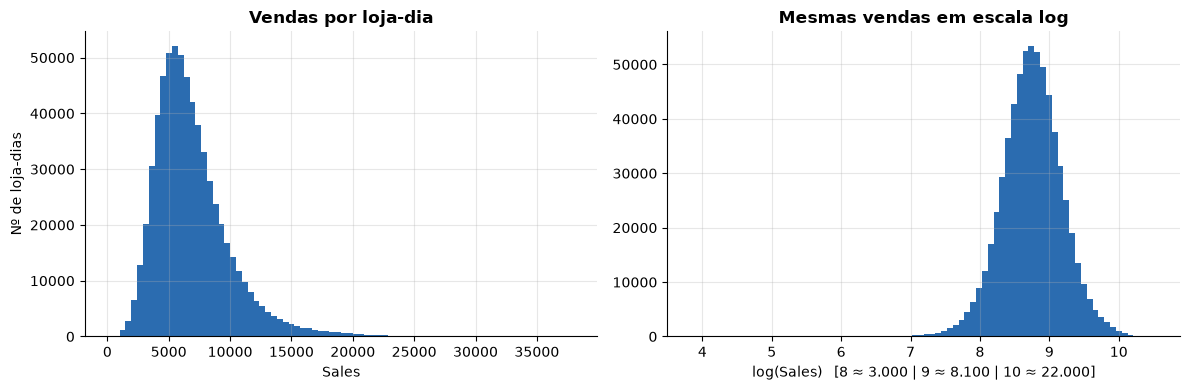

{'count': 648309.0, 'mean': 6916.0, 'std': 3123.0, 'min': 46.0, '25%': 4807.0, '50%': 6318.0, '75%': 8320.0, 'max': 38037.0}
Assimetria: Sales = 1.62 | log(Sales) = -0.1


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(treino.Sales, bins=80, color=AZUL)
ax[0].set(title='Vendas por loja-dia', xlabel='Sales', ylabel='Nº de loja-dias')
ax[1].hist(np.log(treino.Sales), bins=80, color=AZUL)
ax[1].set(title='Mesmas vendas em escala log', xlabel='log(Sales)   [8 ≈ 3.000 | 9 ≈ 8.100 | 10 ≈ 22.000]')
plt.tight_layout(); plt.show()

print(treino.Sales.describe().round(0).to_dict())
print('Assimetria: Sales =', round(treino.Sales.skew(), 2), '| log(Sales) =', round(np.log(treino.Sales).skew(), 2))

Cada barra conta quantos **loja-dias** (uma loja em um dia, somando todas as lojas) tiveram venda naquela faixa. A soma de todas as barras dá as 648.309 linhas do treino.

A venda típica de uma loja-dia fica entre 4.807 e 8.320 (do 1º ao 3º quartil), com mediana de 6.318. A cauda à direita é longa e vai até 38.037, e a assimetria é de 1,62. No log, a distribuição fica quase simétrica (−0,10). Por isso, na Parte 2, todos os modelos treinam em `log(Sales)` e devolvem a previsão de volta na escala de vendas.

### 8.2 Diferença entre lojas

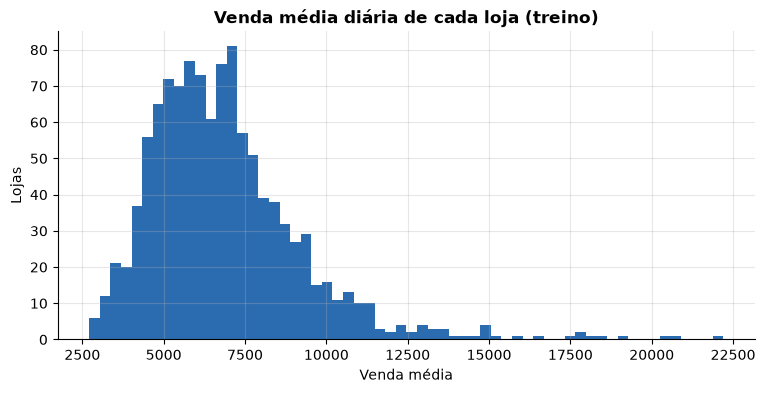

Menor média: 2714 | maior: 22203 | razão: 8.2
Variação das vendas explicada só pela média de cada loja: 59.8%


In [15]:
media_loja = treino.groupby('Store').Sales.mean()
fig, ax = plt.subplots()
ax.hist(media_loja, bins=60, color=AZUL)
ax.set(title='Venda média diária de cada loja (treino)', xlabel='Venda média', ylabel='Lojas')
plt.show()

print('Menor média:', round(media_loja.min()), '| maior:', round(media_loja.max()), '| razão:', round(media_loja.max() / media_loja.min(), 1))
r2_loja = r2_score(treino.Sales, treino.Store.map(media_loja))
print(f'Variação das vendas explicada só pela média de cada loja: {r2_loja:.1%}')

A loja que mais vende fatura em média 8,2 vezes mais que a que menos vende. **Só saber qual é a loja explica 59,8% da variação das vendas.** É o fator mais forte da base inteira, e as features de calendário e promoção têm que explicar o que sobra.

Por isso `Store` não entra no X como número (o código 500 não é "maior" que o 499). Na Parte 2, o histórico da loja entra como média de vendas calculada dentro de cada dobra (seção 13), e o grupo do K-means é testado como coluna extra (seção 14).

### 8.3 Período do ano

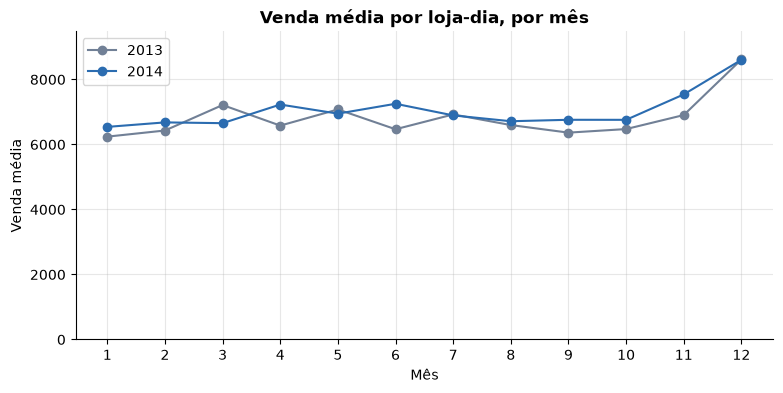

mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2013,6241,6429,7213,6580,7077,6468,6924,6596,6364,6473,6905,8613
2014,6540,6679,6655,7228,6948,7251,6894,6714,6759,6758,7540,8604


Dezembro sobre a média dos outros meses: +27.1%


In [16]:
mensal = treino.groupby(['ano', 'mes']).Sales.mean().unstack(0)
fig, ax = plt.subplots()
for ano, cor in zip(mensal.columns, [CINZA, AZUL]):
    ax.plot(mensal.index, mensal[ano], marker='o', color=cor, label=str(ano))
ax.set(title='Venda média por loja-dia, por mês', xlabel='Mês', ylabel='Venda média', xticks=range(1, 13),
       ylim=(0, mensal.max().max() * 1.1))
ax.legend(); plt.show()

display(mensal.round(0).astype(int).T)
print('Dezembro sobre a média dos outros meses:',
      f"{treino[treino.mes == 12].Sales.mean() / treino[treino.mes != 12].Sales.mean() - 1:+.1%}")

Dezembro vende 27,1% acima da média dos outros meses, nos dois anos. O resto do ano é bem mais estável, entre 6.241 e 7.540. Como o teste vai de janeiro a julho, o pico de dezembro não está nele. Isso deixa o teste um pouco mais fácil que o ano completo, e precisa ser dito quando formos comparar com o artigo.

### 8.4 Dia da semana

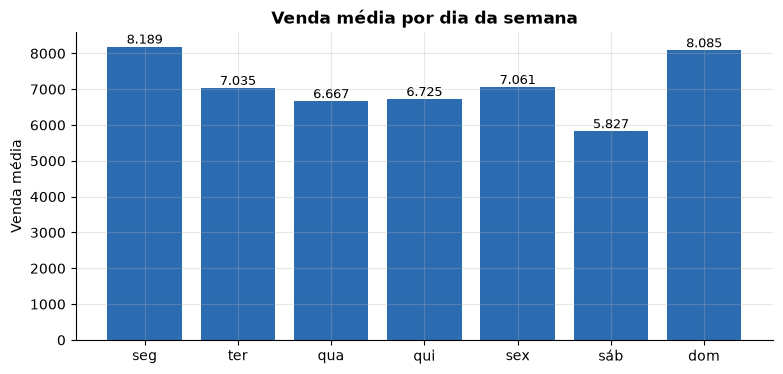

,venda_media,lojas_dia,dias_com_promo
DayOfWeek,,,
seg,8188.96,106327,0.55
ter,7034.51,110840,0.53
qua,6666.58,108505,0.53
qui,6724.69,102956,0.54
sex,7061.34,106286,0.52
sáb,5827.30,110624,0.00
dom,8084.93,2771,0.00


Lojas que abriram em algum domingo: 33


In [17]:
nomes_dia = {1: 'seg', 2: 'ter', 3: 'qua', 4: 'qui', 5: 'sex', 6: 'sáb', 7: 'dom'}
por_dia = treino.groupby('DayOfWeek').agg(venda_media=('Sales', 'mean'), lojas_dia=('Sales', 'size'),
                                          dias_com_promo=('Promo', 'mean'))
por_dia.index = por_dia.index.map(nomes_dia)

fig, ax = plt.subplots()
barras = ax.bar(por_dia.index, por_dia.venda_media, color=AZUL)
ax.bar_label(barras, labels=[br(v) for v in por_dia.venda_media], fontsize=9)
ax.set(title='Venda média por dia da semana', ylabel='Venda média')
plt.show()
display(por_dia.round(2))
print('Lojas que abriram em algum domingo:', treino[treino.DayOfWeek == 7].Store.nunique())

Segunda é o dia mais forte (8.189) e sábado o mais fraco (5.827). O domingo tem média alta, mas são só 2.771 loja-dias de 33 lojas, já que quase todas fecham.

A coluna `dias_com_promo` mostra que a `Promo` **nunca** acontece no fim de semana. Comparar a venda com e sem promoção sem separar por dia da semana mistura os dois efeitos, então a próxima célula compara dentro de cada dia.

### 8.5 Promoções

Venda média sem Promo: 5,900 | com Promo: 8,208 | diferença: +39.1%


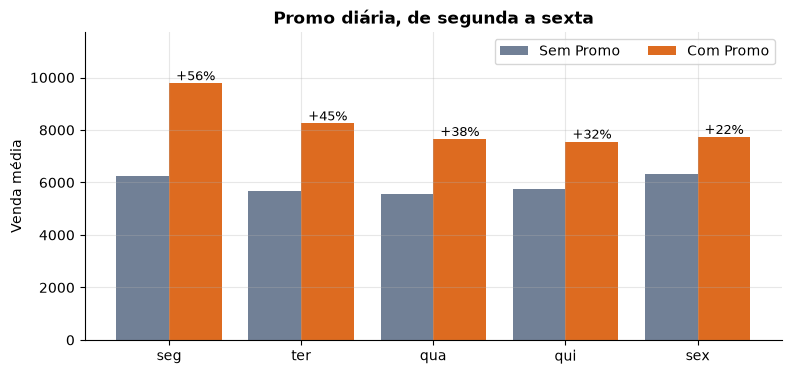

Promo,0,1,efeito
DayOfWeek,,,
seg,6255.28,9780.03,0.56
ter,5677.10,8249.72,0.45
qua,5559.25,7655.51,0.38
qui,5737.17,7557.24,0.32
sex,6327.78,7735.03,0.22


Efeito da Promo por loja: mediana +40.7%, de -9.1% a +147.1%


In [18]:
promo = treino.groupby('Promo').Sales.mean()
print(f'Venda média sem Promo: {promo[0]:,.0f} | com Promo: {promo[1]:,.0f} | diferença: {promo[1] / promo[0] - 1:+.1%}')

# Mesma comparação dentro de cada dia útil, para não misturar com o efeito do dia
promo_dia = treino[treino.DayOfWeek <= 5].groupby(['DayOfWeek', 'Promo']).Sales.mean().unstack()
promo_dia.index = promo_dia.index.map(nomes_dia)
promo_dia['efeito'] = promo_dia[1] / promo_dia[0] - 1

fig, ax = plt.subplots()
x = np.arange(len(promo_dia))
ax.bar(x - 0.2, promo_dia[0], 0.4, color=CINZA, label='Sem Promo')
com = ax.bar(x + 0.2, promo_dia[1], 0.4, color=LARANJA, label='Com Promo')
ax.bar_label(com, labels=[f'{e:+.0%}' for e in promo_dia.efeito], fontsize=9)
ax.set(title='Promo diária, de segunda a sexta', xticks=x, xticklabels=promo_dia.index, ylabel='Venda média',
       ylim=(0, promo_dia[1].max() * 1.2))
ax.legend(ncol=2, loc='upper right'); plt.show()
display(promo_dia.round(2))

efeito_loja = treino.groupby(['Store', 'Promo']).Sales.mean().unstack()
efeito_loja = efeito_loja[1] / efeito_loja[0] - 1
print(f'Efeito da Promo por loja: mediana {efeito_loja.median():+.1%}, de {efeito_loja.min():+.1%} a {efeito_loja.max():+.1%}')

Com `Promo`, a venda média sobe 39,1%. O efeito aparece em todos os dias úteis e diminui ao longo da semana: +56% na segunda e +22% na sexta.

Por loja, a mediana do efeito é de +40,7%, mas varia de −9,1% a +147,1%. Esse é um dos critérios do K-means da Parte 2, que vai separar as lojas que dependem de promoção das que não dependem.

In [19]:
p2 = treino.groupby('Promo2').Sales.mean()
print(f'Venda média: lojas fora da Promo2 = {p2[0]:,.0f} | lojas na Promo2 = {p2[1]:,.0f} ({p2[1] / p2[0] - 1:+.1%})')
ativa = treino[treino.Promo2 == 1].groupby('promo2_ativa').Sales.mean()
print(f'Só lojas da Promo2: mês fora do ciclo = {ativa[0]:,.0f} | mês do ciclo = {ativa[1]:,.0f} ({ativa[1] / ativa[0] - 1:+.1%})')
display(treino.groupby('PromoInterval').agg(lojas=('Store', 'nunique'), venda_media=('Sales', 'mean')).round(0))

Venda média: lojas fora da Promo2 = 7,315 | lojas na Promo2 = 6,510 (-11.0%)
Só lojas da Promo2: mês fora do ciclo = 6,565 | mês do ciclo = 6,366 (-3.0%)


,lojas,venda_media
PromoInterval,,
"Feb,May,Aug,Nov",130,6392.0
"Jan,Apr,Jul,Oct",335,6669.0
"Mar,Jun,Sept,Dec",106,6181.0
Nenhum,544,7315.0


A Promo2 vai na direção contrária. As lojas que participam vendem 11,0% **menos**, e dentro delas o mês do ciclo vende 3,0% menos que o mês fora do ciclo. Isso não quer dizer que a Promo2 derruba as vendas. **Dedução nossa**, que os dados não confirmam: a Rossmann pode ter colocado a Promo2 justamente nas lojas mais fracas. Isso é correlação, não causa. As variáveis ficam no modelo, e a importância delas na Parte 2 mostra se ajudam a prever.

### 8.6 Feriados

In [20]:
bruto_treino = vendas[pd.to_datetime(vendas.Date) < CORTE]
fechou = bruto_treino.groupby(bruto_treino.StateHoliday.map(mapa_feriado)).Open.apply(lambda o: (o == 0).mean())
fer = treino.groupby('StateHoliday').agg(lojas_dia=('Sales', 'size'), lojas=('Store', 'nunique'), venda_media=('Sales', 'mean'))
fer['% das lojas fechadas no dia'] = (fechou * 100).round(1)
display(fer.sort_values('lojas_dia', ascending=False).round(0))

esc = treino.groupby('SchoolHoliday').Sales.mean()
print(f'Férias escolares: {esc[1]:,.0f} contra {esc[0]:,.0f} fora delas ({esc[1] / esc[0] - 1:+.1%})')
vesp = treino.groupby('vespera_feriado').Sales.mean()
pos = treino.groupby('pos_feriado').Sales.mean()
print(f'Véspera de feriado: {vesp[1]:,.0f} contra {vesp[0]:,.0f} ({vesp[1] / vesp[0] - 1:+.1%})')
print(f'Dia seguinte a feriado: {pos[1]:,.0f} contra {pos[0]:,.0f} ({pos[1] / pos[0] - 1:+.1%})')

,lojas_dia,lojas,venda_media,% das lojas fechadas no dia
StateHoliday,,,,
Nenhum,647641,1115,6914.0,14.0
Feriado público,501,153,8258.0,97.0
Páscoa,96,32,9566.0,98.0
Natal,71,20,9744.0,98.0


Férias escolares: 7,076 contra 6,875 fora delas (+2.9%)
Véspera de feriado: 7,312 contra 6,906 (+5.9%)
Dia seguinte a feriado: 7,626 contra 6,892 (+10.7%)


Em feriado, 97% a 98% das lojas fecham, então quase todo o efeito do feriado já saiu com os dias fechados. As poucas que abrem vendem mais (8.258 a 9.744), mas são só 668 loja-dias no total, e uma média dessas é pouco confiável.

O efeito aparece **em volta** do feriado: a venda é 5,9% maior na véspera e 10,7% maior no dia seguinte. Por isso `vespera_feriado` e `pos_feriado` são candidatas, e a seção 14 testa se elas melhoram a validação. Férias escolares mexem pouco: +2,9%.

### 8.7 Tipo de loja e sortimento

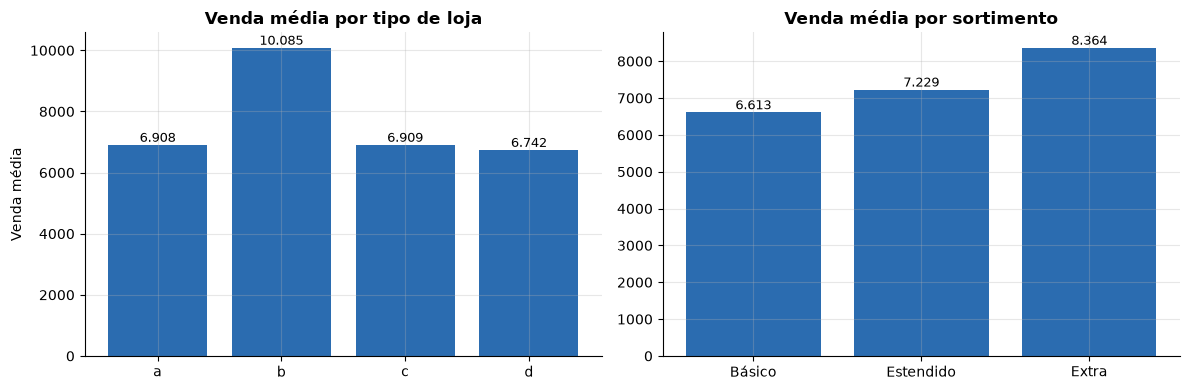

,lojas,venda_media,clientes_medios,ticket_medio
StoreType,,,,
a,602,6908.10,800.50,8.63
b,17,10085.46,2007.06,5.02
c,148,6908.56,819.91,8.43
d,348,6741.64,605.43,11.14


,lojas,venda_media
Assortment,,
Básico,593,6613.0
Estendido,513,7229.0
Extra,9,8364.0


Assortment,Básico,Estendido,Extra
StoreType,,,
a,381,221,0
b,7,1,9
c,77,71,0
d,128,220,0


Venda média do tipo b sobre a dos outros tipos juntos: +47%


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tipo = treino.groupby('StoreType').agg(lojas=('Store', 'nunique'), venda_media=('Sales', 'mean'), clientes_medios=('Customers', 'mean'))
soma = treino.groupby('StoreType')[['Sales', 'Customers']].sum()
tipo['ticket_medio'] = soma.Sales / soma.Customers
sort = treino.groupby('Assortment').agg(lojas=('Store', 'nunique'), venda_media=('Sales', 'mean'))
b0 = ax[0].bar(tipo.index, tipo.venda_media, color=AZUL); ax[0].set(title='Venda média por tipo de loja', ylabel='Venda média')
b1 = ax[1].bar(sort.index, sort.venda_media, color=AZUL); ax[1].set(title='Venda média por sortimento')
for a, b in zip(ax, [b0, b1]):
    a.bar_label(b, labels=[br(v) for v in b.datavalues], fontsize=9)
plt.tight_layout(); plt.show()
display(tipo.round(2)); display(sort.round(0))
display(pd.crosstab(lojas.StoreType, lojas.Assortment.map(mapa_sortimento)))
venda_b, venda_outros = treino[treino.StoreType == 'b'].Sales.mean(), treino[treino.StoreType != 'b'].Sales.mean()
print(f'Venda média do tipo b sobre a dos outros tipos juntos: {venda_b / venda_outros - 1:+.0%}')

O tipo `b` é diferente dos outros: vende 47% mais que os outros tipos juntos. São só 17 lojas, mas cada uma vende em média 10.085 por dia e recebe 2.007 clientes, mais que o dobro das outras. O ticket médio dele é o menor (5,02). O tipo `d` é o contrário: menos clientes e o maior ticket (11,14). Entre `a`, `c` e `d`, a venda média é quase a mesma.

O sortimento `Extra` existe em só 9 lojas, todas do tipo `b`. Então "Extra vende mais" e "tipo b vende mais" são, na prática, o mesmo efeito. Como são poucas lojas, o one-hot de `Extra` vai ter pouco dado para aprender.

### 8.8 Concorrência

In [22]:
por_loja = treino.groupby('Store').agg(venda_media=('Sales', 'mean'), dist=('CompetitionDistance', 'first'))
por_loja['faixa'] = pd.qcut(por_loja.dist, 5)
faixas = por_loja.groupby('faixa', observed=True).agg(lojas=('venda_media', 'size'), venda_media=('venda_media', 'mean'))
display(faixas.round(0))
print('Correlação de Spearman (distância x venda média da loja):',
      round(por_loja.dist.corr(por_loja.venda_media, method='spearman'), 3))

mc = treino.dropna(subset=['meses_competicao'])
faixa_tempo = pd.cut(mc.meses_competicao, [-1, 0, 12, 60, 10_000],
                     labels=['ainda não abriu / mês 0', 'até 1 ano', '1 a 5 anos', 'mais de 5 anos'])
display(mc.groupby(faixa_tempo, observed=True).Sales.agg(['size', 'mean']).round(0))

,lojas,venda_media
faixa,,
"(19.999, 520.0]",226,7562.0
"(520.0, 1600.0]",221,6728.0
"(1600.0, 3450.0]",221,6661.0
"(3450.0, 8666.0]",221,6722.0
"(8666.0, 75860.0]",223,6780.0


Correlação de Spearman (distância x venda média da loja): -0.035


,size,mean
meses_competicao,,
ainda não abriu / mês 0,69951,7238.0
até 1 ano,49235,7163.0
1 a 5 anos,138793,6904.0
mais de 5 anos,183556,6787.0


A distância do concorrente quase não se relaciona com a venda média da loja (Spearman de −0,035). A exceção é o quinto mais próximo, até 520 m, que vende mais (7.562 contra 6.661 a 6.780 nas outras quatro faixas). **Dedução nossa**, que a base não confirma porque não tem localização: concorrente muito perto costuma indicar rua comercial, onde todo mundo vende mais.

Pelo tempo de concorrência, as lojas vendem um pouco mais quando o concorrente ainda não abriu (7.238) do que quando ele está lá há mais de 5 anos (6.787). O artigo-base aponta a distância do concorrente como um dos fatores que mais pesam no modelo de árvore. Aqui, sozinha, ela pesa pouco. As duas coisas podem ser verdade, porque a árvore combina variáveis, então a Parte 2 confere isso.

### 8.9 Clientes

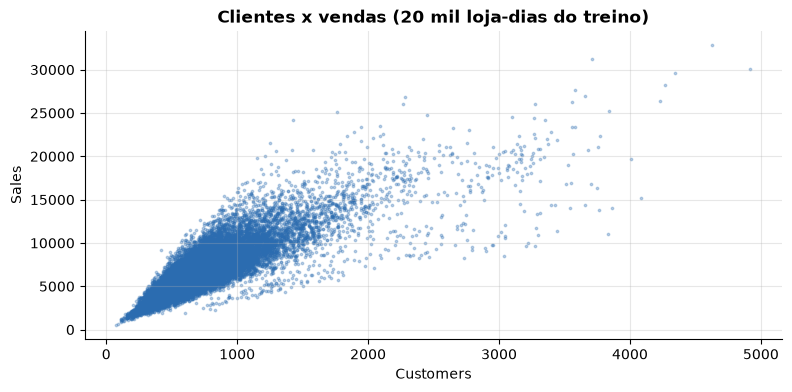

Correlação Customers x Sales no treino: 0.829


In [23]:
amostra = treino.sample(20_000, random_state=SEED)
fig, ax = plt.subplots()
ax.scatter(amostra.Customers, amostra.Sales, s=3, alpha=0.3, color=AZUL)
ax.set(title='Clientes x vendas (20 mil loja-dias do treino)', xlabel='Customers', ylabel='Sales')
plt.show()
print('Correlação Customers x Sales no treino:', round(treino.Customers.corr(treino.Sales), 3))

Correlação de 0,829 no treino. Isso confirma por que `Customers` não pode entrar no X: um modelo com ela pareceria muito bom, mas não daria para usar, porque ninguém sabe o número de clientes de amanhã.

### O que a EDA mostrou

| Fator | O que os dados mostram | Força |
|---|---|---|
| Qual é a loja | Sozinha explica 59,8% da variação | Muito forte |
| Promoção diária (`Promo`) | +39,1% em média, de +22% a +56% conforme o dia | Forte |
| Dezembro | +27,1% sobre os outros meses | Forte, mas fora do teste |
| Dia da semana | Segunda 8.189 contra sábado 5.827 | Médio |
| Véspera e dia seguinte a feriado | +5,9% e +10,7% | Médio (candidatas, seção 14) |
| Tipo de loja | Tipo `b` vende 47% mais que os outros tipos juntos | Forte em poucas lojas |
| Promo2 | −11,0%, provavelmente porque foi dada às lojas mais fracas | Fraco e confundido |
| Distância do concorrente | Spearman −0,035 | Fraco sozinho |
| Férias escolares | +2,9% | Fraco |

### O que isso muda no plano

1. **Histórico da loja é obrigatório.** Sem ele, qualquer modelo começa perdendo os 59,8% que a média da loja explica. Ele entra na Parte 2 calculado dentro de cada dobra.
2. **O efeito da promoção depende da loja e do dia.** Isso favorece árvores e boosting, que combinam variáveis sozinhos. Nos modelos lineares, precisaríamos criar essas interações à mão.
3. **Variáveis candidatas para a Parte 2:** véspera/pós-feriado e o grupo do K-means. Cada uma só entra se melhorar a validação cruzada, nunca o teste.

## 9. Pré-processamento das colunas da linha

Tudo que **aprende** com os dados fica dentro de um `ColumnTransformer`. Assim, na validação cruzada ele é ajustado de novo em cada dobra, e no teste vale o que foi aprendido no treino.

| Grupo | Colunas | Transformação | Aprende com os dados? |
|---|---|---|---|
| Numéricas com nulo | `CompetitionDistance`, `meses_competicao` | Mediana + coluna indicadora de nulo | Sim (a mediana) |
| Diretas | `Promo`, `SchoolHoliday`, `Promo2`, `promo2_ativa`, `vespera_feriado`, `pos_feriado`, `DayOfWeek`, `ano`, `mes`, `dia`, `semana_ano` | Passam direto | Não |
| Categóricas | `StoreType`, `Assortment`, `StateHoliday`, `PromoInterval` | One-hot. Categoria que não apareceu no treino vira tudo zero | Sim (a lista de categorias) |

Na seção 13 entram mais dois blocos que também aprendem dentro do pipeline: o histórico de vendas da loja e o grupo do K-means. A padronização (`StandardScaler`) entra só no pipeline do SVR, porque árvores não dependem de escala.

In [24]:
ALVO = 'Sales'
NUM_COM_NULO = ['CompetitionDistance', 'meses_competicao']
BINARIAS = ['Promo', 'SchoolHoliday', 'Promo2', 'promo2_ativa']
FERIADO_VIZINHO = ['vespera_feriado', 'pos_feriado']
CALENDARIO = ['DayOfWeek', 'ano', 'mes', 'dia', 'semana_ano']
CATEGORICAS = ['StoreType', 'Assortment', 'StateHoliday', 'PromoInterval']
FEATURES = NUM_COM_NULO + BINARIAS + FERIADO_VIZINHO + CALENDARIO + CATEGORICAS
FORA = sorted(set(treino.columns) - set(FEATURES) - {ALVO})

print(len(FEATURES), 'features:', FEATURES)
print('Fora do X:', FORA)
print('Categorias de cada coluna no treino:', {c: sorted(treino[c].unique()) for c in CATEGORICAS})

17 features: ['CompetitionDistance', 'meses_competicao', 'Promo', 'SchoolHoliday', 'Promo2', 'promo2_ativa', 'vespera_feriado', 'pos_feriado', 'DayOfWeek', 'ano', 'mes', 'dia', 'semana_ano', 'StoreType', 'Assortment', 'StateHoliday', 'PromoInterval']
Fora do X: ['Customers', 'Date', 'Store']
Categorias de cada coluna no treino: {'StoreType': ['a', 'b', 'c', 'd'], 'Assortment': ['Básico', 'Estendido', 'Extra'], 'StateHoliday': ['Feriado público', 'Natal', 'Nenhum', 'Páscoa'], 'PromoInterval': ['Feb,May,Aug,Nov', 'Jan,Apr,Jul,Oct', 'Mar,Jun,Sept,Dec', 'Nenhum']}


São 17 colunas no X. As categóricas têm no máximo 4 valores, então não há categoria rara para agrupar. Com isso, a crítica do projeto 1 sobre escolher "categorias frequentes" fora das dobras não se aplica aqui. Mesmo assim, a lista de categorias é aprendida dentro do pipeline.

In [25]:
def preprocessador_base():
    """Pré-processamento das colunas da própria linha. O que aprende (mediana, categorias) só aprende no fit."""
    return ColumnTransformer([
        ('num_nulos', SimpleImputer(strategy='median', add_indicator=True), NUM_COM_NULO),
        ('diretas', 'passthrough', BINARIAS + FERIADO_VIZINHO + CALENDARIO),
        ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAS),
    ], verbose_feature_names_out=False)

prep = preprocessador_base().fit(treino[FEATURES])
Xt = prep.transform(treino[FEATURES])
print('Matriz de treino transformada:', Xt.shape, '| nulos restantes:', int(np.isnan(Xt).sum()))
print('Medianas aprendidas no treino:', {c: float(m) for c, m in zip(NUM_COM_NULO, prep.named_transformers_['num_nulos'].statistics_)})
print('Colunas geradas:', list(prep.get_feature_names_out()))

Matriz de treino transformada: (648309, 30) | nulos restantes: 0
Medianas aprendidas no treino: {'CompetitionDistance': 2330.0, 'meses_competicao': 47.0}
Colunas geradas: ['CompetitionDistance', 'meses_competicao', 'missingindicator_CompetitionDistance', 'missingindicator_meses_competicao', 'Promo', 'SchoolHoliday', 'Promo2', 'promo2_ativa', 'vespera_feriado', 'pos_feriado', 'DayOfWeek', 'ano', 'mes', 'dia', 'semana_ano', 'StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_Básico', 'Assortment_Estendido', 'Assortment_Extra', 'StateHoliday_Feriado público', 'StateHoliday_Natal', 'StateHoliday_Nenhum', 'StateHoliday_Páscoa', 'PromoInterval_Feb,May,Aug,Nov', 'PromoInterval_Jan,Apr,Jul,Oct', 'PromoInterval_Mar,Jun,Sept,Dec', 'PromoInterval_Nenhum']


Ficaram 30 colunas e nenhum nulo. As medianas foram aprendidas só com o treino: 2.330 m de distância e 47 meses de concorrência.

## 10. Validação cruzada temporal e baseline

Esta é a etapa de **validação**. A ideia é a mesma do k-fold com 5 dobras da Aula 2: o treino é dividido em 5 partes, e em cada rodada uma parte diferente serve de validação. A média e o desvio das 5 rodadas mostram o desempenho e a estabilidade do modelo.

A diferença é a ordem. O `KFold` comum embaralha e validaria, por exemplo, março de 2013 com um modelo treinado em 2014, ou seja, usando o futuro para prever o passado. O `TimeSeriesSplit` é o k-fold para dados no tempo:

| | `KFold(5)` comum | `TimeSeriesSplit(5)` (o que usamos) |
|---|---|---|
| Validação | Uma parte sorteada | As 6 semanas logo depois do treino da dobra |
| Treino da dobra | As outras 4 partes, passado e futuro misturados | Só o passado. Cresce a cada dobra |
| Problema em série temporal | Vaza o futuro e dá resultado otimista | Nenhum, porque imita o uso real |

São 5 janelas de 42 datas, cerca de 6 semanas, o mesmo horizonte de previsão da competição. Depois de escolher o modelo pelas 5 dobras, ele é treinado de novo com o treino inteiro (2013–2014) e avaliado **uma vez** no teste.

In [26]:
datas = np.sort(treino.Date.unique())
tss = TimeSeriesSplit(n_splits=5, test_size=42)
DOBRAS = []
for i_tr, i_va in tss.split(datas):
    DOBRAS.append((np.flatnonzero(treino.Date.isin(datas[i_tr])),
                   np.flatnonzero(treino.Date.isin(datas[i_va]))))
    print(f'dobra {len(DOBRAS)}: treina até {pd.Timestamp(datas[i_tr][-1]).date()} | valida {pd.Timestamp(datas[i_va][0]).date()} a {pd.Timestamp(datas[i_va][-1]).date()}')

dobra 1: treina até 2014-06-04 | valida 2014-06-05 a 2014-07-16
dobra 2: treina até 2014-07-16 | valida 2014-07-17 a 2014-08-27
dobra 3: treina até 2014-08-27 | valida 2014-08-28 a 2014-10-08
dobra 4: treina até 2014-10-08 | valida 2014-10-09 a 2014-11-19
dobra 5: treina até 2014-11-19 | valida 2014-11-20 a 2014-12-31


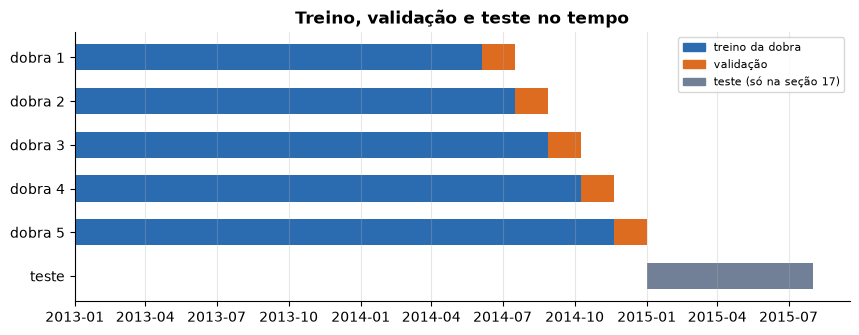

In [27]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch

def faixa(ax, linha, datas, cor):
    """Desenha uma barra horizontal do primeiro ao último dia de um conjunto."""
    ini, fim = mdates.date2num(datas.min()), mdates.date2num(datas.max())
    ax.barh(linha, fim - ini + 1, left=ini, color=cor, height=0.6)

fig, ax = plt.subplots(figsize=(10, 3.5))
for k, (i_tr, i_va) in enumerate(DOBRAS, 1):
    faixa(ax, k, treino.Date.iloc[i_tr], AZUL)
    faixa(ax, k, treino.Date.iloc[i_va], LARANJA)
faixa(ax, 6, teste.Date, CINZA)
ax.set(yticks=range(1, 7), yticklabels=[f'dobra {k}' for k in range(1, 6)] + ['teste'],
       title='Treino, validação e teste no tempo')
ax.xaxis_date(); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=AZUL, label='treino da dobra'), Patch(color=LARANJA, label='validação'),
                   Patch(color=CINZA, label='teste (só na seção 17)')], loc='upper right', fontsize=8)
plt.show()

No gráfico, o azul é o treino de cada dobra e o laranja a validação. O treino cresce a cada dobra, e a validação vem sempre logo depois dele. O teste (cinza) fica de fora de todas. As dobras cobrem de junho a dezembro de 2014. Todas caem no período sem as 180 lojas, e a dobra 5 pega o Natal.

### Baseline e métricas

O baseline é uma previsão feita por regra simples, sem Machine Learning. As métricas medem a previsão, e não o modelo, então o baseline já pode ser avaliado aqui, nas mesmas dobras e com as mesmas métricas que os modelos da Parte 2 vão usar. Ele dá o mínimo que um modelo precisa bater. São três regras, cada uma aprendida só com a parte de treino da dobra:

| Regra | O que prevê |
|---|---|
| Média global | O mesmo valor para toda loja e todo dia |
| Média da loja | A venda média daquela loja |
| Média loja × dia da semana × Promo | A venda média daquela loja naquele dia da semana, com ou sem promoção |

| Métrica | O que mede | Como ler |
|---|---|---|
| MAE | Média dos erros, em valor absoluto | "Erra, em média, X por loja por dia." Fica na unidade da venda |
| RMSE | Como o MAE, mas eleva os erros ao quadrado antes da média | Pesa mais os erros grandes. Muito acima do MAE indica alguns erros enormes |
| R² | Quanto da variação das vendas a previsão explica | 1 = tudo. 0 = igual a prever sempre a média. Negativo = pior que isso |
| RMSPE | Como o RMSE, mas com o erro em percentual da venda real | É a métrica da competição do Kaggle |

In [28]:
def rmspe(y, p):
    """Raiz do erro percentual quadrático médio (métrica da competição)."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    return np.sqrt(np.mean(((y - p) / y) ** 2))

def metricas(y, p):
    """As quatro métricas usadas no projeto, na mesma ordem em todas as tabelas."""
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)),
            'R2': r2_score(y, p), 'RMSPE': rmspe(y, p)}

def media_global(tr, va):
    return np.full(len(va), tr.Sales.mean())

def media_loja(tr, va):
    return va.Store.map(tr.groupby('Store').Sales.mean()).fillna(tr.Sales.mean()).to_numpy()

def media_loja_dia_promo(tr, va):
    tab = tr.groupby(['Store', 'DayOfWeek', 'Promo']).Sales.mean().rename('p')
    p = va.join(tab, on=['Store', 'DayOfWeek', 'Promo']).p.to_numpy()
    return np.where(np.isnan(p), media_loja(tr, va), p)

BASELINES = {'Média global': media_global, 'Média da loja': media_loja,
             'Média loja x dia da semana x Promo': media_loja_dia_promo}
linhas = []
for nome, f in BASELINES.items():
    for k, (i_tr, i_va) in enumerate(DOBRAS, 1):
        tr, va = treino.iloc[i_tr], treino.iloc[i_va]
        linhas.append({'modelo': nome, 'dobra': k, **metricas(va.Sales, f(tr, va))})

res_base = pd.DataFrame(linhas)
display(res_base.pivot(index='modelo', columns='dobra', values='RMSPE').round(3))
resumo_base = res_base.groupby('modelo')[['MAE', 'RMSE', 'R2', 'RMSPE']].agg(['mean', 'std']).sort_values(('MAE', 'mean'), ascending=False)
display(resumo_base.round(3))

dobra,1,2,3,4,5
modelo,,,,,
Média da loja,0.32,0.34,0.33,0.31,0.85
Média global,0.56,0.59,0.58,0.56,0.97
Média loja x dia da semana x Promo,0.14,0.14,0.15,0.14,0.61


MAE             RMSE            R2  \
                                       mean     std     mean     std  mean   
modelo                                                                       
Média global                        2341.46  340.08  3201.06  528.81 -0.04   
Média da loja                       1553.90  410.22  2067.10  542.79  0.57   
Média loja x dia da semana x Promo   919.63  498.64  1326.83  674.24  0.82   

                                         RMSPE        
                                     std  mean   std  
modelo                                                
Média global                        0.07  0.65  0.18  
Média da loja                       0.11  0.43  0.24  
Média loja x dia da semana x Promo  0.14  0.24  0.21

A média por loja, dia da semana e promoção já chega a **R² de 0,82** e MAE de 920. Sem nenhum modelo de Machine Learning, esse é o número a bater na Parte 2. Para comparação, o Random Forest do artigo chegou a 0,884, mas com outro corte de teste, então os números não são diretamente comparáveis.

A média global tem R² negativo: prever sempre a média do passado é pior do que prever a média da própria janela.

A dobra 5 tem RMSPE muito acima das outras. A próxima célula mostra o motivo.

In [29]:
i_tr, i_va = DOBRAS[-1]
tr, va = treino.iloc[i_tr], treino.iloc[i_va].copy()
va['previsto'] = media_loja_dia_promo(tr, va)
va['erro_pct_quadrado'] = ((va.Sales - va.previsto) / va.Sales) ** 2
display(va.nlargest(5, 'erro_pct_quadrado')[['Store', 'Date', 'Sales', 'Customers', 'previsto', 'erro_pct_quadrado']].round({'previsto': 0, 'erro_pct_quadrado': 1}))
sem_1 = va.erro_pct_quadrado.sort_values().iloc[:-1]
print(f'RMSPE da dobra 5: {rmspe(va.Sales, va.previsto):.3f} | sem a pior linha: {np.sqrt(sem_1.mean()):.3f}')
print('Linhas do treino com Sales abaixo de 500:', (treino.Sales < 500).sum())

,Store,Date,Sales,Customers,previsto,erro_pct_quadrado
29677,652,2014-11-22,46,8,4602.0,9810.0
4158,432,2014-12-24,2363,282,10017.0,10.5
653,786,2014-12-31,856,134,3206.0,7.5
4451,786,2014-12-24,908,138,3206.0,6.4
4477,817,2014-12-24,6052,738,21197.0,6.3


RMSPE da dobra 5: 0.612 | sem a pior linha: 0.259
Linhas do treino com Sales abaixo de 500: 6


Uma única linha, a loja 652 em 22/11/2014, vendeu 46 com 8 clientes. Ela sozinha leva o RMSPE da dobra de 0,259 para 0,612. As linhas seguintes são 24 e 31 de dezembro, dias que nenhuma das três regras sabe tratar.

Por isso o RMSPE fica como métrica **secundária**: ele é a métrica da competição, mas um único dia anormal domina o valor. As principais são **MAE, RMSE e R²**, as mesmas da aula de SVR, e o R² também permite comparar com o artigo. O MAE é o critério de escolha, porque está na unidade das vendas e é fácil de explicar: "o modelo erra, em média, X por loja por dia". A linha não foi removida, porque teria que ser por uma regra escolhida depois de ver o erro, e o teste pode ter casos parecidos.

## 11. Resumo da preparação

| Etapa | Resultado |
|---|---|
| Base bruta | 1.017.209 loja-dias, 1.115 lojas |
| Dias de loja fechada removidos | 172.817 |
| Quarentena (aberta com venda zero) | 54 |
| Treino (2013–2014) | 648.309 linhas |
| Teste (jan–jul 2015) | 196.029 linhas, **guardado até a seção 17** |
| Features da linha | 17 colunas, que viram 30 depois do pré-processamento |
| Fora do X | `Customers` (vazamento), `Store` (código; entra só para calcular o histórico da loja), `Date` (já decomposta) |
| Melhor baseline (CV temporal) | Média loja × dia × Promo: MAE 920, R² 0,82 |

### Decisões registradas antes de olhar o teste

| Decisão | Valor |
|---|---|
| Métricas | MAE, RMSE e R² como principais. RMSPE como secundária |
| Validação | `TimeSeriesSplit`, 5 janelas de 42 datas, só no treino (`DOBRAS`) |
| Critério de escolha | Menor MAE médio nas 5 dobras |
| Variáveis candidatas | Véspera/pós-feriado e grupo do K-means. Entram só se baixarem o MAE da validação (seção 14) |
| Uso do teste | Uma vez, na seção 17, com tudo já escolhido |

# Parte 2 — Modelos

## 12. K-means: perfis de loja (aprendizado não supervisionado)

A seção segue as 6 etapas de uma análise de clustering da aula. Cada etapa responde às perguntas do slide:

| Etapa da aula | Pergunta | Resposta curta | Onde |
|---|---|---|---|
| 1. Definir o objetivo | Para que agrupar? Quais objetos? | Achar perfis de loja para decidir promoção, equipe e sortimento. Objetos: as 1.115 lojas | 12.1 |
| 2. Explorar os dados | Distribuições, relações, ausências e outliers? | 7 candidatas exploradas. Clientes e distância têm cauda longa, 3 nulos só na distância, venda média é quase cópia de clientes | 12.2 |
| 3. Preparar as variáveis | Quais atributos? Como tratar? E as escalas? | 3 variáveis. Mediana nos nulos, log(1 + x) e padronização. Sem padronizar, o K-means só enxerga clientes | 12.3 |
| 4. Escolher e executar | Semelhança, algoritmo e parâmetros? | Distância euclidiana, K-means com k-means++ e 20 inícios, K = 3 | 12.4 |
| 5. Avaliar os grupos | Separação, estabilidade e limitações? | Silhueta 0,29 (fronteiras difusas), muito estável, inclusive entre 2013 e 2014 | 12.5 |
| 6. Interpretar e revisar | Perfis? Servem ao objetivo? | 3 perfis com ação sugerida. O perfil formado com 2013 prevê a reação à promoção em 2014 | 12.6 |

### 12.1 Etapa 1 — Definir o objetivo

**Para que agrupar?** A rede tem 1.115 lojas, e a EDA mostrou que elas reagem de jeitos muito diferentes: o efeito da promoção vai de −9% a +147% conforme a loja (seção 8.5). Tratar todas do mesmo jeito desperdiça recurso. Uma promoção numa loja que quase não reage custa margem e traz pouca venda, e uma equipe dimensionada pela média fica sobrando numa loja e faltando em outra.

A pergunta do agrupamento é: **que tipos de loja existem, e o que fazer diferente em cada um?** A base não tem uma coluna com essa resposta, então os grupos precisam ser descobertos. Por isso é um problema não supervisionado.

| Decisão que o agrupamento apoia | O que precisamos saber da loja |
|---|---|
| Onde concentrar as promoções | Quanto a venda sobe quando tem promoção |
| Quantos funcionários e caixas | Quantos clientes entram por dia |
| Sortimento e ações para aumentar o gasto | Quanto cada cliente gasta |

**Quais objetos?** As **lojas**. Cada uma das 1.115 lojas vira uma linha, com o resumo do comportamento dela calculado **só com o treino** (2013–2014). O dia de venda não é o objeto aqui, porque a decisão é tomada por loja.

A média de clientes usada aqui é a média histórica da loja, que já é conhecida antes de qualquer dia do futuro. O número de clientes **do próprio dia** continua fora do modelo de previsão.

### 12.2 Etapa 2 — Explorar os dados

Calculamos, para cada loja, sete candidatas a variável do agrupamento. A primeira célula mostra os valores e as relações entre elas. A segunda mostra distribuições, ausências e outliers.

In [30]:
def perfil_lojas(dados, vendas_y):
    """Perfil de comportamento de cada loja, calculado só com as linhas recebidas (treino).
    Usa a média HISTÓRICA de clientes; o número de clientes do dia nunca entra no modelo."""
    d = dados[['Store', 'Promo', 'Customers']].assign(Sales=np.asarray(vendas_y))
    g = d.groupby('Store')
    perfil = pd.DataFrame({'clientes_dia': g.Customers.mean(),
                           'ticket': g.Sales.sum() / g.Customers.sum()})
    pr = d.groupby(['Store', 'Promo']).Sales.mean().unstack()
    perfil['efeito_promo'] = np.log(pr[1] / pr[0])
    return perfil

def matriz_kmeans(perfil):
    """Mesma preparação do caso de clustering da aula: mediana nos nulos -> log(1+x) -> padronização."""
    bruto = np.column_stack([np.log1p(perfil.clientes_dia), np.log1p(perfil.ticket), perfil.efeito_promo])
    prep_km = Pipeline([('mediana', SimpleImputer(strategy='median')), ('padroniza', StandardScaler())])
    return prep_km.fit_transform(bruto)

perfil = perfil_lojas(treino, treino.Sales)

# Outras variáveis candidatas, também só com o treino. Servem para decidir o que entra na distância.
sem_promo = treino[treino.Promo == 0]
dia_loja = sem_promo.groupby(['Store', 'DayOfWeek']).Sales.mean().unstack()
venda_loja = treino.groupby('Store').Sales.mean()
CANDIDATAS_KM = perfil.assign(
    venda_media=venda_loja,
    forca_sabado=dia_loja[6] / dia_loja[[1, 2, 3, 4, 5]].mean(axis=1),
    efeito_dezembro=treino[treino.mes == 12].groupby('Store').Sales.mean()
                    / treino[treino.mes != 12].groupby('Store').Sales.mean() - 1,
    dist_concorrente=lojas.set_index('Store').CompetitionDistance)
print('Lojas:', len(CANDIDATAS_KM), '| nulos:', CANDIDATAS_KM.isna().sum()[lambda s: s > 0].to_dict())
display(CANDIDATAS_KM.describe().T[['mean', '50%', 'min', 'max']].round(3))
print('Correlação de Spearman entre as candidatas:')
display(CANDIDATAS_KM.corr(method='spearman').round(2))

Z = matriz_kmeans(perfil)

Lojas: 1115 | nulos: {'dist_concorrente': 3}


,mean,50%,min,max
clientes_dia,756.34,681.69,242.37,3424.34
ticket,9.56,9.38,3.49,15.95
efeito_promo,0.34,0.34,-0.10,0.91
venda_media,6889.31,6572.32,2714.23,22203.04
forca_sabado,0.99,1.00,0.36,1.70
efeito_dezembro,0.27,0.27,-0.15,0.69
dist_concorrente,5404.90,2325.00,20.00,75860.00


Correlação de Spearman entre as candidatas:


,clientes_dia,ticket,efeito_promo,venda_media,forca_sabado,efeito_dezembro,dist_concorrente
clientes_dia,1.00,-0.51,-0.13,0.80,-0.03,-0.12,-0.28
ticket,-0.51,1.00,-0.01,0.06,0.30,0.13,0.47
efeito_promo,-0.13,-0.01,1.00,-0.17,-0.66,0.05,0.01
venda_media,0.80,0.06,-0.17,1.00,0.17,-0.05,-0.03
forca_sabado,-0.03,0.30,-0.66,0.17,1.00,0.05,-0.08
efeito_dezembro,-0.12,0.13,0.05,-0.05,0.05,1.00,0.28
dist_concorrente,-0.28,0.47,0.01,-0.03,-0.08,0.28,1.00


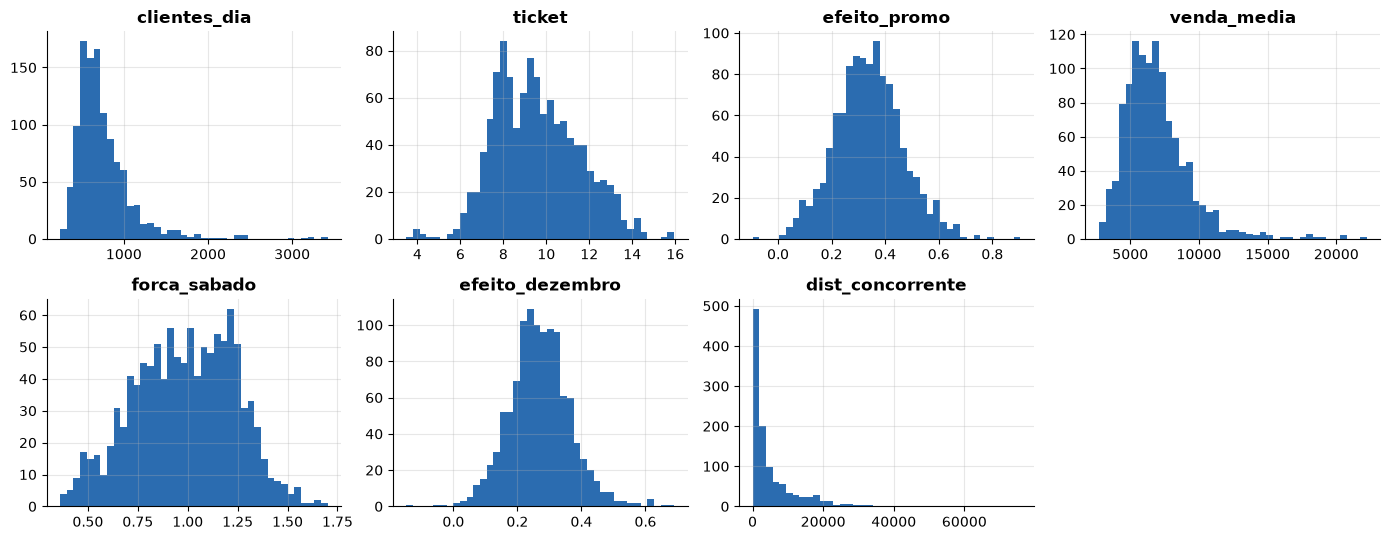

,nulos,"outliers (1,5 x IQR)",assimetria
clientes_dia,0,53,2.99
ticket,0,5,0.27
efeito_promo,0,13,0.21
venda_media,0,36,1.75
forca_sabado,0,0,-0.13
efeito_dezembro,0,24,0.26
dist_concorrente,3,108,2.93


Lojas com mais clientes por dia: {262: 3424.0, 733: 3413.0, 817: 3212.0}
Lojas que vendem MENOS com promoção: 1


In [31]:
# Distribuições: um histograma por candidata
cols = list(CANDIDATAS_KM.columns)
fig, axs = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, c in zip(axs.ravel(), cols):
    ax.hist(CANDIDATAS_KM[c].dropna(), bins=40, color=AZUL)
    ax.set(title=c)
axs.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

# Ausências e outliers (regra de 1,5 x IQR, a mesma do boxplot)
q1, q3 = CANDIDATAS_KM.quantile(0.25), CANDIDATAS_KM.quantile(0.75)
fora = (CANDIDATAS_KM < q1 - 1.5 * (q3 - q1)) | (CANDIDATAS_KM > q3 + 1.5 * (q3 - q1))
display(pd.DataFrame({'nulos': CANDIDATAS_KM.isna().sum(),
                      'outliers (1,5 x IQR)': fora.sum(),
                      'assimetria': CANDIDATAS_KM.skew().round(2)}))
print('Lojas com mais clientes por dia:', CANDIDATAS_KM.clientes_dia.nlargest(3).round(0).to_dict())
print('Lojas que vendem MENOS com promoção:', int((CANDIDATAS_KM.efeito_promo < 0).sum()))

**Distribuições.** `clientes_dia` (assimetria 2,99), `venda_media` (1,75) e `dist_concorrente` (2,93) têm cauda longa à direita: poucas lojas com valores muito acima do resto. Ticket, efeito da promoção, força do sábado e efeito de dezembro são quase simétricos.

**Relações** (correlação de Spearman, tabela anterior):
- `venda_media` × `clientes_dia` = 0,80. A venda média é quase uma cópia do número de clientes, o que faz sentido, já que venda = clientes × ticket.
- `forca_sabado` × `efeito_promo` = −0,66. As lojas que mais reagem à promoção são as de sábado fraco.
- `ticket` × `clientes_dia` = −0,51. Lojas cheias têm ticket menor.
- O efeito da promoção quase não se relaciona com clientes (−0,13) nem com ticket (−0,01).

**Ausências.** Só `dist_concorrente` tem nulos (3 lojas, as mesmas da seção 2). As outras seis estão completas.

**Outliers.** Pela regra de 1,5 × IQR, há 53 lojas fora do padrão em clientes por dia (as maiores passam de 3.200 clientes) e 108 na distância do concorrente. Elas **não são removidas**: são lojas reais, e o objetivo é dar um perfil a todas. O tratamento é o log da etapa 3, que reduz o peso desses extremos na distância. Só 1 loja vende menos com promoção.

### 12.3 Etapa 3 — Preparar as variáveis

**Seleção de atributos.** Com a exploração, escolhemos três variáveis, uma para cada decisão do objetivo:

| Candidata | O que diz sobre a loja | Entra na distância? | Por quê |
|---|---|---|---|
| `clientes_dia` | Movimento: quantos clientes por dia | **Sim** | Responde à decisão de equipe e caixas |
| `ticket` | Quanto cada cliente gasta | **Sim** | Responde à decisão de sortimento. A correlação de −0,51 com clientes mostra que traz informação diferente |
| `efeito_promo` | Quanto a venda sobe com promoção | **Sim** | É a decisão principal, e quase não se relaciona com as outras duas |
| `venda_media` | Porte da loja | Não | É clientes × ticket (correlação de 0,80 com clientes). Entraria como cópia e contaria o movimento duas vezes, como o gasto total no caso da aula |
| `forca_sabado` (dia da semana) | Sábado comparado aos dias úteis | Não, só descreve | Correlação de −0,66 com o efeito da promoção. Colocar as duas pesaria duas vezes quase a mesma informação. O padrão semanal de cada perfil aparece na etapa 6 |
| `efeito_dezembro` | Quanto dezembro sobe | Não, só descreve | Vale para a rede inteira e já está no modelo de previsão pelo calendário. Não muda nenhuma das três decisões |
| `dist_concorrente` | Localização | Não, só descreve | É contexto, não comportamento de venda |

O efeito da promoção está como log da razão "venda com promoção / venda sem promoção". Assim, +0,34 corresponde a cerca de +40%, e a loja que vende menos com promoção fica negativa.

**Tratamento.** Mesma sequência da aula: mediana nos nulos (nas três escolhidas não há nenhum, mas a etapa fica no código para proteger contra loja nova sem dado) → log(1 + x) em clientes e ticket, por causa da cauda longa → padronização.

**Avaliar escalas.** A célula abaixo mostra o que acontece se a padronização for pulada.

In [32]:
bruto = perfil[['clientes_dia', 'ticket', 'efeito_promo']]
print('Desvio padrão sem padronizar:', bruto.std().round(3).to_dict())
g_bruto = KMeans(3, n_init=20, random_state=SEED).fit_predict(bruto)
g_so_clientes = KMeans(3, n_init=20, random_state=SEED).fit_predict(bruto[['clientes_dia']])
g_padronizado = KMeans(3, n_init=20, random_state=SEED).fit_predict(Z)
print(f'Concordância (ARI) sem padronizar x usando só clientes_dia: {adjusted_rand_score(g_bruto, g_so_clientes):.3f}')
print(f'Concordância (ARI) sem padronizar x padronizado:            {adjusted_rand_score(g_bruto, g_padronizado):.3f}')
print('Medianas dos grupos SEM padronizar:')
display(bruto.assign(grupo=g_bruto).groupby('grupo').median().round(2))

Desvio padrão sem padronizar: {'clientes_dia': 355.592, 'ticket': 1.963, 'efeito_promo': 0.126}
Concordância (ARI) sem padronizar x usando só clientes_dia: 0.993
Concordância (ARI) sem padronizar x padronizado:            0.242
Medianas dos grupos SEM padronizar:


,clientes_dia,ticket,efeito_promo
grupo,,,
0,594.94,9.96,0.35
1,988.27,8.15,0.31
2,2266.98,6.97,0.19


Sem padronizar, `clientes_dia` varia na casa das centenas (desvio de 356), o ticket na casa das unidades (2,0) e o efeito da promoção em décimos (0,13). O resultado é um K-means que, na prática, **só olha o número de clientes**: a divisão sem padronizar concorda 99,3% (ARI 0,993) com a divisão feita só com clientes. O efeito da promoção, que é a decisão principal, não define nenhum grupo: só acompanha o tamanho (0,35, 0,31 e 0,19). Os grupos separam lojas pequenas, médias e grandes e não servem para decidir onde fazer promoção.

Depois de padronizar, cada variável fica com média 0 e desvio 1 e pesa igual na distância. A divisão muda completamente (ARI de só 0,24 com a versão sem padronizar).

### 12.4 Etapa 4 — Escolher e executar

**Semelhança: distância euclidiana.** É a que o K-means usa por definição: ele coloca cada loja no centro mais próximo e move os centros para reduzir a soma das distâncias ao quadrado. Faz sentido aqui porque as três variáveis são numéricas e contínuas e, depois do log e da padronização, estão na mesma escala e sem extremos fortes.

| Alternativa de semelhança | O que muda | Por que não usamos |
|---|---|---|
| Manhattan (soma das diferenças absolutas) | Sofre menos com extremos | Exige outro algoritmo (K-medianas ou K-medoides). Depois do log, os extremos já pesam pouco |
| Cosseno | Compara só a proporção entre as variáveis e ignora o tamanho | Duas lojas com o mesmo formato, uma com o dobro de clientes, ficariam iguais. O tamanho importa para a decisão de equipe |

**Algoritmo: K-means.** As variáveis são numéricas, queremos um número fixo de perfis e **toda** loja precisa receber um perfil (um método que deixa pontos como "ruído", como o DBSCAN, deixaria lojas sem estratégia). Com 1.115 lojas, ele roda em segundos, e o centro de cada grupo já é o "retrato" do perfil.

**Parâmetros:** início `k-means++`, `n_init = 20` (o algoritmo começa 20 vezes e guarda o melhor resultado), `random_state = 42` e o número de grupos K, escolhido abaixo.

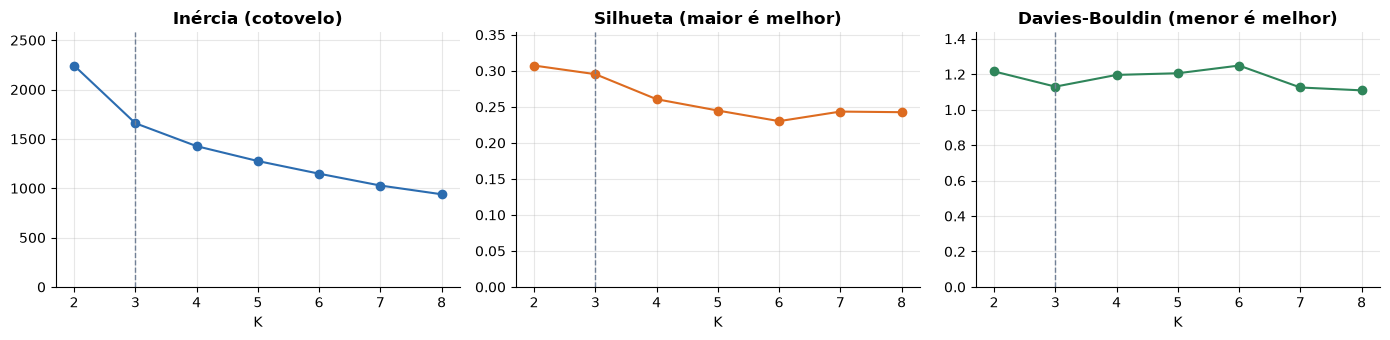

,inércia,queda da inércia,silhueta,Davies-Bouldin
K,,,,
2,2242.98,NaN,0.31,1.22
3,1658.68,-0.26,0.29,1.13
4,1426.35,-0.14,0.26,1.20
5,1275.54,-0.11,0.24,1.21
6,1147.39,-0.10,0.23,1.25
7,1027.40,-0.10,0.24,1.12
8,938.84,-0.09,0.24,1.11


In [33]:
ks = range(2, 9)
inercia, silhueta, db = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(Z)
    inercia.append(km.inertia_)
    silhueta.append(silhouette_score(Z, km.labels_))
    db.append(davies_bouldin_score(Z, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
paineis = [(inercia, 'Inércia (cotovelo)', AZUL), (silhueta, 'Silhueta (maior é melhor)', LARANJA),
           (db, 'Davies-Bouldin (menor é melhor)', VERDE)]
for a, (serie, nome, cor) in zip(ax, paineis):
    a.plot(ks, serie, marker='o', color=cor)
    a.axvline(3, color=CINZA, ls='--', lw=1)
    a.set(title=nome, xlabel='K', ylim=(0, max(serie) * 1.15))
plt.tight_layout(); plt.show()
tab_k = pd.DataFrame({'inércia': inercia, 'silhueta': silhueta, 'Davies-Bouldin': db}, index=pd.Index(ks, name='K'))
tab_k.insert(1, 'queda da inércia', tab_k['inércia'].pct_change())
display(tab_k.round(3))

Os três painéis começam o eixo no zero, para a diferença entre os valores não parecer maior do que é. A linha tracejada marca K = 3, o valor escolhido abaixo.

Três critérios olham o K, e nenhum decide sozinho:

- **Inércia (cotovelo):** sempre cai quando K aumenta. A maior queda é de K = 2 para K = 3 (de 2.243 para 1.659, −26%, na coluna "queda da inércia"). Depois a queda diminui (−14% de 3 para 4), e esse é o cotovelo.
- **Silhueta** (maior é melhor): um pouco maior com K = 2 (0,31) do que com K = 3 (0,29). De K = 4 em diante, cai.
- **Davies-Bouldin** (menor é melhor): K = 3 tem o melhor valor entre 2 e 6 (1,13). K = 7 e 8 empatam praticamente (1,12 e 1,11), mas com silhueta menor e grupos demais para virar estratégia.

O critério de negócio fecha a escolha: são três decisões (promoção, equipe e sortimento), e **três perfis bastam** para dar uma estratégia a cada alavanca. Ficamos com **K = 3**. A etapa 5 confere se essa escolha é estável.

### 12.5 Etapa 5 — Avaliar os grupos

In [34]:
K = 3
km_final = KMeans(n_clusters=K, init='k-means++', n_init=20, random_state=SEED).fit(Z)
grupos = km_final.labels_

# 1) Inícios diferentes: n_init=1 (um sorteio só) contra n_init=20
ari_1 = [adjusted_rand_score(grupos, KMeans(K, n_init=1, random_state=s).fit_predict(Z)) for s in range(20)]
ari_20 = [adjusted_rand_score(grupos, KMeans(K, n_init=20, random_state=s).fit_predict(Z)) for s in range(20)]

# 2) Subamostras de 80% das lojas: o agrupamento se repete?
rng = np.random.RandomState(SEED)
ari_sub = []
for _ in range(30):
    i = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    km = KMeans(K, n_init=10, random_state=SEED).fit(Z[i])
    ari_sub.append(adjusted_rand_score(grupos, km.predict(Z)))

display(pd.DataFrame({'ARI mínimo': [min(ari_1), min(ari_20), min(ari_sub)],
                      'ARI mediano': [np.median(ari_1), np.median(ari_20), np.median(ari_sub)]},
                     index=['20 inícios simples (n_init=1)', '20 execuções com n_init=20', '30 subamostras de 80%']).round(3))
print(f'Separação com K={K}: silhueta {silhouette_score(Z, grupos):.3f} | Davies-Bouldin {davies_bouldin_score(Z, grupos):.3f}')

# 3) Validação no tempo: agrupa as lojas com os dados de 2013 e, separado, com os de 2014
t13, t14 = treino[treino.ano == 2013], treino[treino.ano == 2014]
p13, p14 = perfil_lojas(t13, t13.Sales), perfil_lojas(t14, t14.Sales)
comuns = p13.index.intersection(p14.index)
temporal = {}
for k in range(2, 6):
    g13 = pd.Series(KMeans(k, n_init=20, random_state=SEED).fit_predict(matriz_kmeans(p13)), index=p13.index)
    g14 = pd.Series(KMeans(k, n_init=20, random_state=SEED).fit_predict(matriz_kmeans(p14)), index=p14.index)
    temporal[k] = adjusted_rand_score(g13[comuns], g14[comuns])
    if k == K:
        g13_k = g13
display(pd.Series(temporal).rename_axis('K').to_frame('ARI 2013 x 2014').round(3))

,ARI mínimo,ARI mediano
20 inícios simples (n_init=1),0.95,0.98
20 execuções com n_init=20,0.98,0.99
30 subamostras de 80%,0.89,0.95


Separação com K=3: silhueta 0.295 | Davies-Bouldin 1.130


,ARI 2013 x 2014
K,
2,0.87
3,0.82
4,0.80
5,0.73


**Separação:** silhueta de 0,29 e Davies-Bouldin de 1,13. Os grupos existem, mas com fronteiras difusas: há lojas no meio do caminho entre dois perfis.

**Estabilidade:** três testes, do mais simples ao mais exigente.

| Teste | O que pergunta | Resultado |
|---|---|---|
| Inícios diferentes | O resultado depende da sorte do início? | Com `n_init = 20`, ARI mínimo de 0,98. Não depende |
| Subamostras de 80% das lojas | Se faltassem lojas, os grupos seriam os mesmos? | ARI mediano de 0,95, mínimo de 0,89 |
| **2013 × 2014** | Agrupando cada ano separado, as mesmas lojas caem juntas? | ARI de **0,82** com K = 3 |

O teste no tempo funciona como uma validação cruzada do agrupamento: o perfil de cada loja é calculado duas vezes, com dados que não se misturam. K = 2 se repete um pouco mais (0,87), e K = 4 e K = 5 se repetem menos (0,80 e 0,73). K = 3 mantém uma concordância alta com uma estratégia a mais que K = 2.

A próxima célula mostra qual variável mais define os grupos.

In [35]:
nomes_var = ['clientes_dia', 'ticket', 'efeito_promo']
sens = {}
for j, nome in enumerate(nomes_var):
    Z_sem = np.delete(Z, j, axis=1)
    outra = KMeans(K, n_init=20, random_state=SEED).fit_predict(Z_sem)
    z = pd.Series(Z[:, j])
    var_entre = 1 - ((z - z.groupby(grupos).transform('mean')) ** 2).sum() / ((z - z.mean()) ** 2).sum()
    sens[nome] = {'variação entre grupos': var_entre, 'ARI ao retirar a variável': adjusted_rand_score(grupos, outra)}
display(pd.DataFrame(sens).T.round(3))

,variação entre grupos,ARI ao retirar a variável
clientes_dia,0.47,0.67
ticket,0.54,0.56
efeito_promo,0.51,0.37


"Variação entre grupos" mostra quanto da variação de cada variável fica entre os grupos (quanto maior, mais ela diferencia os perfis). O ARI mostra quanto a divisão muda ao retirar a variável (quanto menor, mais ela pesa).

O **efeito da promoção** é a variável que mais define os grupos: sem ela, a concordância cai para 0,37. Isso é coerente com o objetivo, já que a decisão principal é onde fazer promoção. Ticket (0,56) e clientes por dia (0,67) também pesam, então as três ficam.

**Limitações**
- A silhueta perto de 0,3 mostra que os perfis são tendências, não caixas fechadas. Uma loja na fronteira pode se comportar como dois perfis.
- K = 2 é um pouco mais estável no tempo que K = 3. A escolha de K = 3 é pela utilidade, e isso fica registrado.
- Os perfis usam dois anos de dados (2013–2014), e 180 lojas não têm o 2º semestre de 2014.
- O K-means mostra quais lojas se parecem. Ele não explica **por que** são assim, porque a base não tem localização, tamanho da loja nem público.

### 12.6 Etapa 6 — Interpretar e revisar

* variáveis que entraram na distância; as outras só descrevem o grupo


grupo,A - Dependentes de promoção,B - Movimentadas de ticket baixo,C - Ticket alto e pouco movimento
lojas,399,326,390
clientes por dia *,639 (537 a 741),"983 (846 a 1,190)",559 (471 a 673)
ticket médio *,9.23 (8.30 a 10.10),7.77 (7.13 a 8.38),11.35 (10.27 a 12.37)
efeito da promoção *,+56%,+32%,+33%
venda média por dia,5779.0,7617.0,6282.0
sábado / dia útil (sem promo),0.76,1.02,1.18
efeito de dezembro,+27%,+24%,+28%
tipo de loja mais comum,a (72%),a (65%),d (64%)
sortimento mais comum,Básico (66%),Básico (56%),Estendido (62%)
concorrente mais próximo (m),2565.0,790.0,4435.0


Centro de cada perfil, em desvios-padrão em relação à loja média da rede (0 = loja média):


,clientes_dia,ticket,efeito_promo
A - Dependentes de promoção,-0.26,-0.07,0.95
B - Movimentadas de ticket baixo,1.04,-0.96,-0.55
C - Ticket alto e pouco movimento,-0.60,0.88,-0.52


Exemplo: distância da loja 1 até cada centro: {'A': 2.07, 'B': 1.7, 'C': 1.49} -> perfil C


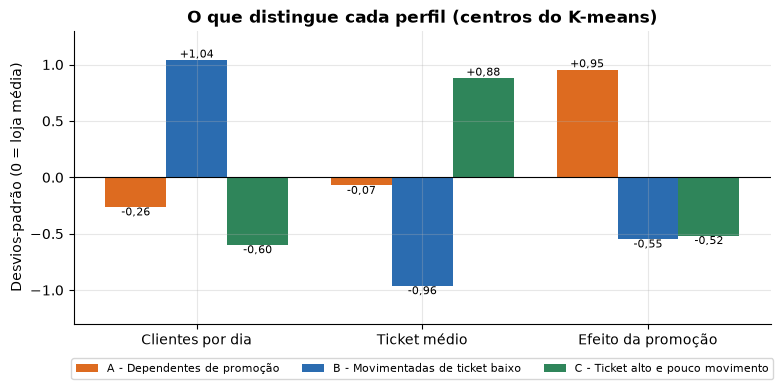

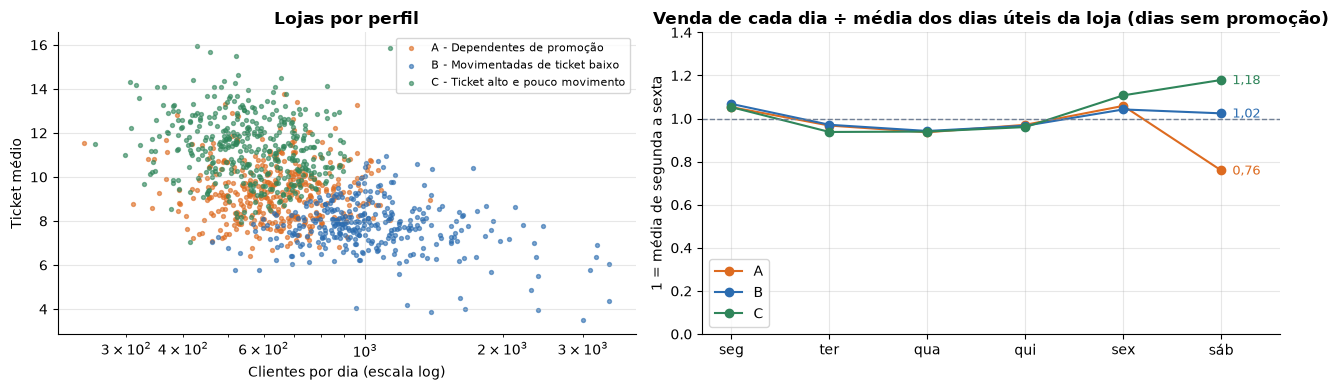

In [36]:
# Nomeia os grupos pelo perfil, e não pelo número que o K-means sorteou (o número pode mudar entre versões)
med = perfil.groupby(grupos)[['clientes_dia', 'ticket', 'efeito_promo']].median()
g_a = med.efeito_promo.idxmax()
g_b = med.drop(g_a).clientes_dia.idxmax()
g_c = med.drop([g_a, g_b]).index[0]
letra = {g_a: 'A', g_b: 'B', g_c: 'C'}
NOMES = {'A': 'A - Dependentes de promoção', 'B': 'B - Movimentadas de ticket baixo', 'C': 'C - Ticket alto e pouco movimento'}
perfil['grupo'] = pd.Series(grupos, index=perfil.index).map(letra)

info = treino.groupby('Store').agg(StoreType=('StoreType', 'first'), Assortment=('Assortment', 'first'), Promo2=('Promo2', 'first'))
perfil = perfil.join(info).join(CANDIDATAS_KM[['venda_media', 'forca_sabado', 'efeito_dezembro', 'dist_concorrente']])

def mediana_iqr(s, casas=2):
    # Mediana e intervalo P25-P75, como na tabela de perfis da aula
    return f'{s.median():,.{casas}f} ({s.quantile(.25):,.{casas}f} a {s.quantile(.75):,.{casas}f})'

def mais_comum(s):
    # Categoria mais frequente do grupo e a sua participação
    v = s.value_counts(normalize=True)
    return f'{v.index[0]} ({v.iloc[0]:.0%})'

g = perfil.groupby('grupo')
FICHA = pd.DataFrame({
    'lojas': g.size(),
    'clientes por dia *': g.clientes_dia.apply(mediana_iqr, casas=0),
    'ticket médio *': g.ticket.apply(mediana_iqr),
    'efeito da promoção *': g.efeito_promo.median().apply(lambda v: f'{np.expm1(v):+.0%}'),
    'venda média por dia': g.venda_media.median().round(0),
    'sábado / dia útil (sem promo)': g.forca_sabado.median().round(2),
    'efeito de dezembro': g.efeito_dezembro.median().apply(lambda v: f'{v:+.0%}'),
    'tipo de loja mais comum': g.StoreType.apply(mais_comum),
    'sortimento mais comum': g.Assortment.apply(mais_comum),
    'concorrente mais próximo (m)': g.dist_concorrente.median().round(0),
    'lojas na Promo2': g.Promo2.mean().apply(lambda v: f'{v:.0%}'),
}).T.rename(columns=NOMES)
print('* variáveis que entraram na distância; as outras só descrevem o grupo')
display(FICHA)

cores = {'A': LARANJA, 'B': AZUL, 'C': VERDE}
VARS_KM = ['clientes_dia', 'ticket', 'efeito_promo']
CENTROS = pd.DataFrame(km_final.cluster_centers_, columns=VARS_KM).rename(index=letra).sort_index()
print('Centro de cada perfil, em desvios-padrão em relação à loja média da rede (0 = loja média):')
display(CENTROS.rename(index=NOMES).round(2))

loja_ex = 1
dist = np.linalg.norm(km_final.cluster_centers_ - Z[perfil.index.get_loc(loja_ex)], axis=1)
print(f'Exemplo: distância da loja {loja_ex} até cada centro:',
      dict(sorted((letra[i], round(float(d), 2)) for i, d in enumerate(dist))), '-> perfil', perfil.grupo[loja_ex])

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(VARS_KM))
for j, (gr, cor) in enumerate(cores.items()):
    b = ax.bar(x + (j - 1) * 0.27, CENTROS.loc[gr], 0.27, color=cor, label=NOMES[gr])
    ax.bar_label(b, labels=[br(v, 2, sinal=True) for v in CENTROS.loc[gr]], fontsize=8)
ax.axhline(0, color='black', lw=0.8)
ax.set(title='O que distingue cada perfil (centros do K-means)', xticks=x,
       xticklabels=['Clientes por dia', 'Ticket médio', 'Efeito da promoção'],
       ylabel='Desvios-padrão (0 = loja média)')
limite = np.abs(CENTROS.values).max() * 1.25
ax.set_ylim(-limite, limite)
ax.legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1)); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dias = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb']
for gr, cor in cores.items():
    s = perfil[perfil.grupo == gr]
    ax[0].scatter(s.clientes_dia, s.ticket, s=8, alpha=0.6, color=cor, label=NOMES[gr])
    uteis = dia_loja.loc[s.index, 1:5].mean(axis=1)
    padrao = dia_loja.loc[s.index, 1:6].div(uteis, axis=0).median()
    ax[1].plot(dias, padrao.values, marker='o', color=cor, label=gr)
    ax[1].annotate(br(padrao.iloc[-1], 2), (5, padrao.iloc[-1]), textcoords='offset points', xytext=(8, -3), fontsize=9, color=cor)
ax[0].set(xscale='log', title='Lojas por perfil', xlabel='Clientes por dia (escala log)', ylabel='Ticket médio')
ax[0].legend(fontsize=8)
ax[1].axhline(1, color=CINZA, ls='--', lw=1)
ax[1].set(title='Venda de cada dia ÷ média dos dias úteis da loja (dias sem promoção)',
          ylabel='1 = média de segunda a sexta', ylim=(0, 1.4), xlim=(-0.3, 5.6))
ax[1].legend(loc='lower left')
plt.tight_layout(); plt.show()

**Como ler as saídas desta célula**

- **Nomes dos perfis.** O K-means numera os grupos sem nenhum significado, e o número pode mudar entre versões da biblioteca. O código dá a letra por uma regra fixa: **A** é o grupo de maior efeito da promoção, **B** é, entre os outros dois, o de mais clientes por dia, e **C** é o que sobra (aqui, o de maior ticket).
- **Centros.** A tabela e o primeiro gráfico mostram o centro de cada perfil na escala padronizada, em que 0 é a loja média da rede. O que distingue cada perfil é a barra que mais se afasta do zero: promoção no A (+0,95), clientes no B (+1,04) e ticket no C (+0,88).
- **Como uma loja é classificada.** Ela vai para o centro mais próximo. A loja 1 fica a 2,07 do centro A, 1,70 do B e 1,49 do C, então é do perfil C. As distâncias são parecidas, o que mostra uma loja perto da fronteira entre perfis.
- **Ficha.** Mediana de cada perfil nas variáveis da distância (marcadas com *) e nas descritivas.

**Perfil A — Dependentes de promoção (399 lojas)**
- **Como é:** movimento e ticket no meio da rede (639 clientes por dia e ticket de 9,23), mas a promoção aumenta a venda em **+56%**, quase o dobro dos outros perfis. O sábado é o dia mais fraco: 0,76 da média dos dias úteis, ou seja, 24% a menos. Maioria tipo `a` (72%) e sortimento básico (66%).
- **O que fazer (sugestão nossa):** concentrar aqui as campanhas, que é onde cada promoção rende mais. Reforçar estoque e equipe nos dias de promoção. Fora da promoção a venda cai bastante, então o planejamento desses dias deve ser mais enxuto, principalmente no sábado.

**Perfil B — Movimentadas de ticket baixo (326 lojas)**
- **Como é:** o maior movimento da rede (983 clientes por dia) e a maior venda média (7.617), mas cada cliente gasta pouco (ticket de 7,77). O concorrente mais próximo fica a 790 m, o mais perto entre os três perfis. A promoção rende +32%, e o sábado vende igual aos dias úteis (1,02).
- **O que fazer (sugestão nossa):** a prioridade é dar conta do fluxo, com caixas abertos e reposição rápida. A alavanca de venda é aumentar o gasto de quem já entra, com combos e itens de maior valor perto do caixa, mais do que atrair gente com promoção.

**Perfil C — Ticket alto e pouco movimento (390 lojas)**
- **Como é:** o menor movimento (559 clientes por dia), mas o maior ticket (11,35). Concorrente longe (4,4 km), maioria tipo `d` (64%) e sortimento estendido (62%). O sábado é o dia mais forte (1,18). A promoção rende +33%.
- **O que fazer (sugestão nossa):** manter o sortimento amplo, que combina com o cliente que compra mais por visita. A alavanca é trazer mais clientes, com comunicação local e fidelidade. Reforçar a equipe no sábado.

**De onde vêm as sugestões.** O algoritmo só separa as lojas. As ações são nossas, com um critério: pegar a variável que mais distingue o perfil (gráfico dos centros) e ligá-la à decisão que ela apoia, definida na etapa 1.

| Afirmação | Situação |
|---|---|
| O perfil A reage mais à promoção | Conferido nos dados, inclusive de um ano para o outro (próxima célula) |
| O perfil A tem sábado fraco e o C tem sábado forte | Conferido nos dados de treino |
| Concentrar promoção no perfil A aumenta o resultado | Hipótese. Mais venda não garante mais lucro, e a base não tem margem nem custo |
| Combos aumentam o ticket do perfil B; comunicação local traz clientes ao C | Hipótese. Precisa de teste na rede |

**Dedução nossa**, que a base não confirma porque não tem a localização das lojas: o perfil B parece de rua comercial, com muita gente, compra rápida e concorrência perto. O perfil C parece de loja mais isolada ou de destino, onde o cliente vem menos vezes e compra mais.

**O que os outros dois gráficos mostram:**
- No gráfico da esquerda, A e C se misturam. Isso é esperado: o que separa o perfil A é o efeito da promoção, que não aparece nesses dois eixos.
- O gráfico da direita mostra o dia da semana. O eixo começa no zero e a linha tracejada é a média dos dias úteis da loja. Cada perfil tem um padrão diferente no sábado: o A cai (0,76), o B fica igual (1,02) e o C sobe (1,18). Como esse padrão acompanha o efeito da promoção (correlação de −0,66), ele aparece nos perfis mesmo sem entrar na distância.
- O efeito de dezembro é parecido nos três perfis (+24% a +28%). A sazonalidade vale para a rede inteira e não separa os tipos de loja.

**Verificar a utilidade para o objetivo.** A próxima célula pergunta se o perfil serve para a decisão principal: com os grupos formados **só com 2013**, olhamos como essas mesmas lojas reagiram à promoção em **2014**.

In [37]:
# Utilidade para o objetivo: os perfis formados com 2013 continuam reagindo diferente à promoção em 2014?
letra_2013 = pd.crosstab(g13_k[comuns], perfil.grupo[comuns]).idxmax(axis=1)
g13_letra = g13_k.map(letra_2013)
print('Lojas que caem no mesmo perfil em 2013 e no treino inteiro:', f'{(g13_letra[comuns] == perfil.grupo[comuns]).mean():.0%}')
display(pd.DataFrame({'efeito da promoção 2013': np.expm1(p13.efeito_promo.groupby(g13_letra).median()),
                      'efeito da promoção 2014 (mesmas lojas)': np.expm1(p14.loc[comuns].efeito_promo.groupby(g13_letra[comuns]).median())})
        .rename(index=NOMES).rename_axis('perfil formado só com 2013').round(3))

Lojas que caem no mesmo perfil em 2013 e no treino inteiro: 96%


,efeito da promoção 2013,efeito da promoção 2014 (mesmas lojas)
perfil formado só com 2013,,
A - Dependentes de promoção,0.54,0.56
B - Movimentadas de ticket baixo,0.30,0.32
C - Ticket alto e pouco movimento,0.32,0.34


Serve. As lojas que formaram o perfil A com os dados de 2013 reagiram +54% à promoção naquele ano e **+56% em 2014**, contra +32% a +34% dos outros perfis. Ou seja, o perfil calculado com o passado **antecipa como a loja vai reagir à promoção no ano seguinte**, que é o que a decisão de onde fazer promoção precisa. 96% das lojas caem no mesmo perfil usando só 2013 ou o treino inteiro.

**Revisões feitas no caminho** ("se o resultado não fizer sentido, revise as escolhas anteriores"):

| Escolha considerada | Problema encontrado | Revisão |
|---|---|---|
| Agrupar sem padronizar | Os grupos viraram "lojas pequenas, médias e grandes" e não separavam a reação à promoção (etapa 3) | Padronizar as três variáveis |
| Usar a venda média | Correlação de 0,80 com clientes: contaria o movimento duas vezes | Venda média só descreve |
| Usar o padrão do dia da semana | Correlação de −0,66 com o efeito da promoção: informação repetida | Dia da semana só descreve, e mesmo assim aparece nos perfis |
| Nomear os grupos pelo número do K-means | O número muda conforme a versão da biblioteca | Nome e letra dados pelo perfil, no código |
| Usar o grupo como coluna do modelo de previsão | Não melhorou a validação (seção 14) | O K-means fica com o papel de entender e segmentar as lojas, que é o objetivo da etapa 1 |

## 13. Pipeline completo

Três peças novas, escritas como transformadores do scikit-learn para ficarem **dentro** do pipeline. Assim cada uma é reajustada em cada dobra da validação cruzada e nunca vê a validação nem o teste.

| Peça | O que faz no `fit` (só treino) | O que faz no `transform` |
|---|---|---|
| `HistoricoLoja` | Calcula a venda média (em log) de cada loja, de cada loja por dia da semana e de cada loja com e sem promoção | Devolve o nível da loja e quanto o dia e a promoção deslocam esse nível |
| `GrupoLoja` | Monta o perfil das lojas e roda o K-means com K = 3 | Devolve o grupo da loja em one-hot, usando só o número da loja |
| `AmostraNoAjuste` | Sorteia linhas e treina o modelo só com elas | Prevê normalmente |

O `AmostraNoAjuste` existe só para o SVR, cujo custo de treino cresce muito com o número de linhas. O pré-processamento antes dele continua vendo o treino inteiro.

**Onde o logaritmo entra.** O log encolhe os valores grandes muito mais que os pequenos e mede proporção: dobrar a venda soma sempre o mesmo valor no log, seja de 1.000 para 2.000 ou de 10.000 para 20.000. Ele aparece em três lugares:

| Onde | Em quê | Para quê |
|---|---|---|
| Alvo de todos os modelos | `Sales` | Tirar o peso da cauda longa (seção 8.1). O `TransformedTargetRegressor` aplica o log no treino e a exponencial na previsão, então as métricas saem na escala de vendas |
| `HistoricoLoja` | Venda média de cada loja | Ficar na mesma escala do alvo |
| K-means (seção 12) | Clientes por dia e ticket, com `log1p` | As lojas muito grandes não puxarem os centros dos grupos |

**As duas células seguintes.** A primeira define as três peças. A segunda tem duas funções: `preprocessador` junta os blocos de colunas e tem chaves para ligar e desligar blocos nos testes das seções 14 e 16, e `montar` encadeia pré-processamento, padronização (só quando o modelo pede) e modelo. No fim, ela faz duas conferências: lista as colunas que saem do pré-processamento e testa se zerar o `Customers` do dia muda alguma previsão.

In [38]:
class HistoricoLoja(BaseEstimator, TransformerMixin):
    """Aprende no fit, só com as linhas de treino, a venda média (em log) de cada loja,
    de cada loja por dia da semana e de cada loja com e sem promoção."""
    def __init__(self, usa_dia=True, usa_promo=True):
        self.usa_dia = usa_dia
        self.usa_promo = usa_promo

    def fit(self, X, y):
        d = X[['Store', 'DayOfWeek', 'Promo']].assign(lv=np.log(np.asarray(y)))
        self.global_ = d.lv.mean()
        self.loja_ = d.groupby('Store').lv.mean()
        self.loja_dia_ = d.groupby(['Store', 'DayOfWeek']).lv.mean()
        self.loja_promo_ = d.groupby(['Store', 'Promo']).lv.mean()
        return self

    def transform(self, X):
        loja = X.Store.map(self.loja_).fillna(self.global_).to_numpy()
        saida = [loja]
        if self.usa_dia:
            dia = self.loja_dia_.reindex(pd.MultiIndex.from_frame(X[['Store', 'DayOfWeek']])).to_numpy()
            saida.append(np.where(np.isnan(dia), loja, dia) - loja)
        if self.usa_promo:
            pro = self.loja_promo_.reindex(pd.MultiIndex.from_frame(X[['Store', 'Promo']])).to_numpy()
            saida.append(np.where(np.isnan(pro), loja, pro) - loja)
        return np.column_stack(saida)

    def get_feature_names_out(self, input_features=None):
        return np.array(['hist_loja'] + ['hist_dia_vs_loja'] * self.usa_dia + ['hist_promo_vs_loja'] * self.usa_promo)


class GrupoLoja(BaseEstimator, TransformerMixin):
    """Roda o K-means das lojas dentro do fit (só com o treino) e devolve o grupo da loja em one-hot.
    Customers é lido só no fit para o perfil histórico; o transform usa apenas o número da loja."""
    def __init__(self, k=3, seed=42):
        self.k = k
        self.seed = seed

    def fit(self, X, y):
        perfil_fit = perfil_lojas(X, y)
        rotulos = KMeans(self.k, n_init=20, random_state=self.seed).fit_predict(matriz_kmeans(perfil_fit))
        self.grupo_ = pd.Series(rotulos, index=perfil_fit.index)
        return self

    def transform(self, X):
        g = X.Store.map(self.grupo_).to_numpy()
        return np.column_stack([(g == i).astype(float) for i in range(self.k)])

    def get_feature_names_out(self, input_features=None):
        return np.array([f'grupo_{i}' for i in range(self.k)])


class AmostraNoAjuste(BaseEstimator, RegressorMixin):
    """Treina o modelo interno com uma amostra sorteada das linhas. Usado só no SVR, cujo custo
    cresce muito com o número de linhas. O pré-processamento antes dele continua vendo o treino inteiro."""
    def __init__(self, estimador=None, n_amostra=6000, seed=42):
        self.estimador = estimador
        self.n_amostra = n_amostra
        self.seed = seed

    def fit(self, X, y):
        i = np.random.RandomState(self.seed).choice(len(X), min(self.n_amostra, len(X)), replace=False)
        self.estimador_ = clone(self.estimador).fit(X[i], np.asarray(y)[i])
        return self

    def predict(self, X):
        return self.estimador_.predict(X)

In [39]:
def preprocessador(feriado_vizinho=True, grupo=True, historico=True, ablacao=False, k=3):
    """Monta o pré-processamento completo. Os parâmetros ligam/desligam blocos para os testes das seções 14 e 16."""
    binarias, calendario, categoricas = BINARIAS, CALENDARIO, CATEGORICAS
    if ablacao:
        binarias = [c for c in BINARIAS if c not in ('Promo', 'SchoolHoliday')]
        calendario = [c for c in CALENDARIO if c != 'DayOfWeek']
        categoricas = [c for c in CATEGORICAS if c != 'StateHoliday']
        feriado_vizinho = False
    diretas = binarias + (FERIADO_VIZINHO if feriado_vizinho else []) + calendario
    partes = [('num_nulos', SimpleImputer(strategy='median', add_indicator=True), NUM_COM_NULO),
              ('diretas', 'passthrough', diretas),
              ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)]
    if historico:
        partes.append(('historico', HistoricoLoja(usa_dia=not ablacao, usa_promo=not ablacao), ['Store', 'DayOfWeek', 'Promo']))
    if grupo and historico:
        partes.append(('grupo_kmeans', GrupoLoja(k=k, seed=SEED), ['Store', 'Promo', 'Customers']))
    return ColumnTransformer(partes, verbose_feature_names_out=False)

def montar(modelo, escalar=False, **cfg):
    """Pipeline = pré-processamento -> (padronização, se o modelo precisa) -> modelo treinado em log(Sales).
    O TransformedTargetRegressor treina em log e devolve a previsão já em escala de vendas (exp)."""
    passos = [('prep', preprocessador(**cfg))]
    if escalar:
        passos.append(('escala', StandardScaler()))
    passos.append(('modelo', TransformedTargetRegressor(regressor=modelo, func=np.log, inverse_func=np.exp)))
    return Pipeline(passos)

COLS_X = FEATURES + ['Store', 'Customers']
X_treino, y_treino = treino[COLS_X], treino[ALVO]
X_teste, y_teste = teste[COLS_X], teste[ALVO]

# Conferência 1: colunas que saem do pré-processamento completo
p = montar(HistGradientBoostingRegressor(random_state=SEED)).fit(X_treino.iloc[DOBRAS[-1][0]], y_treino.iloc[DOBRAS[-1][0]])
nomes = list(p.named_steps['prep'].get_feature_names_out())
print(len(nomes), 'colunas:', nomes)

# Conferência 2: zerar o Customers do dia não pode mudar nada na previsão (prova de que não há vazamento)
X_va = X_treino.iloc[DOBRAS[-1][1]]
print('Previsão idêntica com Customers = 0:', np.allclose(p.predict(X_va), p.predict(X_va.assign(Customers=0))))

36 colunas: ['CompetitionDistance', 'meses_competicao', 'missingindicator_CompetitionDistance', 'missingindicator_meses_competicao', 'Promo', 'SchoolHoliday', 'Promo2', 'promo2_ativa', 'vespera_feriado', 'pos_feriado', 'DayOfWeek', 'ano', 'mes', 'dia', 'semana_ano', 'StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_Básico', 'Assortment_Estendido', 'Assortment_Extra', 'StateHoliday_Feriado público', 'StateHoliday_Natal', 'StateHoliday_Nenhum', 'StateHoliday_Páscoa', 'PromoInterval_Feb,May,Aug,Nov', 'PromoInterval_Jan,Apr,Jul,Oct', 'PromoInterval_Mar,Jun,Sept,Dec', 'PromoInterval_Nenhum', 'hist_loja', 'hist_dia_vs_loja', 'hist_promo_vs_loja', 'grupo_0', 'grupo_1', 'grupo_2']
Previsão idêntica com Customers = 0: True


Com tudo ligado, as 30 colunas da seção 9 viram 36: entram 3 colunas de histórico da loja e 3 do grupo do K-means. Se a seção 14 tirar o grupo, o modelo final fica com 33.

A segunda conferência prova que `Customers` não vaza: trocando o número de clientes de todos os dias da validação por zero, a previsão não muda nada. O `GrupoLoja` só lê essa coluna no `fit`, para montar o perfil histórico das lojas.

## 14. Variáveis candidatas: entram ou não?

A EDA deixou duas candidatas: os dias vizinhos a feriado (seção 8.6) e o grupo do K-means (seção 12). Cada uma só fica se melhorar a **validação cruzada**. O teste usa o mesmo Gradient Boosting com parâmetros padrão nas três versões, para que a única diferença seja a variável.

In [40]:
ESCORES = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

def cv_temporal(pipe):
    """Roda o pipeline nas 5 DOBRAS e devolve as métricas de validação (média e desvio)."""
    r = cross_validate(pipe, X_treino, y_treino, cv=DOBRAS, scoring=ESCORES, error_score='raise')
    tab = pd.DataFrame({'MAE': -r['test_MAE'], 'RMSE': -r['test_RMSE'], 'R2': r['test_R2']})
    return tab.agg(['mean', 'std']).unstack()

hgb_padrao = HistGradientBoostingRegressor(random_state=SEED)
candidatas = pd.DataFrame({
    'completo (feriado vizinho + grupo K-means)': cv_temporal(montar(hgb_padrao)),
    'sem véspera/pós-feriado': cv_temporal(montar(hgb_padrao, feriado_vizinho=False)),
    'sem grupo do K-means': cv_temporal(montar(hgb_padrao, grupo=False)),
}).T
display(candidatas.round(3))

# Decisão registrada aqui, antes de qualquer contato com o teste: a variável fica só se baixar o MAE médio
mae_cand = candidatas[('MAE', 'mean')]
USAR_FERIADO = mae_cand.iloc[0] < mae_cand.iloc[1]
USAR_GRUPO = mae_cand.iloc[0] < mae_cand.iloc[2]
print('Usar véspera/pós-feriado:', USAR_FERIADO, '| usar grupo do K-means como coluna:', USAR_GRUPO)
CFG = dict(feriado_vizinho=USAR_FERIADO, grupo=USAR_GRUPO)

MAE             RMSE          \
                                              mean     std     mean     std   
completo (feriado vizinho + grupo K-means)  697.90  191.75  1018.28  250.56   
sem véspera/pós-feriado                     719.91  188.44  1049.33  252.19   
sem grupo do K-means                        692.48  187.45  1009.61  243.42   

                                              R2        
                                            mean   std  
completo (feriado vizinho + grupo K-means)  0.90  0.03  
sem véspera/pós-feriado                     0.89  0.03  
sem grupo do K-means                        0.90  0.03

Usar véspera/pós-feriado: True | usar grupo do K-means como coluna: False


| Candidata | MAE com | MAE sem | Decisão |
|---|---|---|---|
| Véspera e dia seguinte a feriado | 697,90 | 719,91 | **Fica.** Sem ela o erro sobe 22 por loja-dia |
| Grupo do K-means como coluna | 697,90 | 692,48 | **Sai.** Com ela o erro fica 5,4 maior |

A diferença do grupo é pequena perto do desvio entre dobras (cerca de 190), então na prática ele não acrescenta nada. **Dedução nossa:** o `HistoricoLoja` já dá ao modelo o nível de cada loja e quanto a promoção desloca esse nível, loja por loja. O grupo do K-means é um resumo mais grosso dessa mesma informação, com 3 categorias no lugar de 1.115 lojas.

Isso não tira o K-means do projeto, porque o objetivo dele é outro: dar perfis de loja para orientar promoção, equipe e sortimento (seção 12). Na seção 17, os perfis também mostram em que tipo de loja o modelo erra mais.

## 15. Busca de hiperparâmetros com validação cruzada

Cada modelo passa por um `GridSearchCV` com `cv=DOBRAS`, as mesmas 5 dobras temporais da seção 10. O critério de escolha é o **menor MAE médio de validação**. Depois da busca, o `GridSearchCV` re-treina a melhor combinação no treino inteiro (2013–2014), e é esse modelo que vai para o teste.

| Modelo | Família | Hiperparâmetros testados | O que cada um controla |
|---|---|---|---|
| Árvore de Decisão | Árvore | `max_depth`, `min_samples_leaf` | Quantas perguntas em sequência e quantos dias no mínimo em cada folha |
| Random Forest | Bagging | `max_depth`, `min_samples_leaf` | Complexidade de cada árvore. Fixos: 60 árvores, 50% das colunas por divisão, 20% das linhas por árvore |
| Gradient Boosting | Boosting | `learning_rate`, `max_leaf_nodes` | Tamanho do passo de cada correção e tamanho de cada árvore. Fixo: 300 árvores |
| SVR | Kernel | `C`, `epsilon` | Penalidade para erro fora do tubo e largura do tubo. Kernel RBF com `gamma='scale'`, treino com 6 mil linhas |

Com o alvo em log, `epsilon = 0,05` quer dizer que o SVR ignora erros de até cerca de 5% da venda.

As grades são pequenas de propósito: o objetivo é comparar famílias de modelos com uma regulagem razoável, e cada combinação custa 5 treinos. Esta é a célula mais demorada do notebook.

A busca também guarda o erro no treino de cada dobra, para medir sobreajuste. No SVR isso fica de fora, porque prever o treino inteiro com ele dobraria o tempo.

In [41]:
# Grades pequenas e justificadas: o objetivo é comparar famílias de modelos, não esgotar cada uma.
GRADES = {
    'Árvore de Decisão': (DecisionTreeRegressor(random_state=SEED), False,
                          {'max_depth': [8, 12, 16], 'min_samples_leaf': [20, 100]}),
    'Random Forest': (RandomForestRegressor(n_estimators=60, max_features=0.5, max_samples=0.2,
                                            n_jobs=-1, random_state=SEED), False,
                      {'max_depth': [16, 24], 'min_samples_leaf': [5, 20]}),
    'Gradient Boosting': (HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=SEED), False,
                          {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [31, 63]}),
    'SVR': (AmostraNoAjuste(SVR(kernel='rbf', gamma='scale'), n_amostra=6000, seed=SEED), True,
            {'C': [1, 10], 'epsilon': [0.05, 0.1]}),
}

BUSCAS, tabelas = {}, []
for nome, (modelo, escalar, grade) in GRADES.items():
    t0 = time.time()
    prefixo = 'modelo__regressor__' + ('estimador__' if nome == 'SVR' else '')
    busca = GridSearchCV(montar(modelo, escalar=escalar, **CFG), {prefixo + p: v for p, v in grade.items()},
                         cv=DOBRAS, scoring=ESCORES, refit='MAE',
                         return_train_score=(nome != 'SVR'),
                         error_score='raise')
    busca.fit(X_treino, y_treino)
    BUSCAS[nome] = busca
    r = pd.DataFrame(busca.cv_results_)
    linha = r.loc[busca.best_index_]
    tabelas.append({'modelo': nome, 'melhores parâmetros': {p.split('__')[-1]: v for p, v in busca.best_params_.items()},
                    'MAE validação': -linha.mean_test_MAE,
                    'desvio MAE': np.std([-linha[f'split{i}_test_MAE'] for i in range(5)], ddof=1),
                    'RMSE validação': -linha.mean_test_RMSE, 'R2 validação': linha.mean_test_R2,
                    'MAE treino': -linha.mean_train_MAE if nome != 'SVR' else np.nan,
                    'minutos': (time.time() - t0) / 60})
    print(f'{nome}: {len(r)} combinações x 5 dobras em {(time.time() - t0) / 60:.1f} min')

base_cv = res_base[res_base.modelo == 'Média loja x dia da semana x Promo'][['MAE', 'RMSE', 'R2']]
tabelas.append({'modelo': 'Baseline (média loja x dia x Promo)', 'melhores parâmetros': '-',
                'MAE validação': base_cv.MAE.mean(), 'desvio MAE': base_cv.MAE.std(),
                'RMSE validação': base_cv.RMSE.mean(), 'R2 validação': base_cv.R2.mean(), 'MAE treino': np.nan, 'minutos': 0})
COMPARACAO_CV = pd.DataFrame(tabelas).set_index('modelo').sort_values('MAE validação')
COMPARACAO_CV.insert(6, 'treino abaixo da validação', 1 - COMPARACAO_CV['MAE treino'] / COMPARACAO_CV['MAE validação'])
display(COMPARACAO_CV.round(3))

Árvore de Decisão: 6 combinações x 5 dobras em 2.1 min


Random Forest: 4 combinações x 5 dobras em 5.0 min


Gradient Boosting: 4 combinações x 5 dobras em 7.4 min


SVR: 4 combinações x 5 dobras em 3.2 min


,melhores parâmetros,MAE validação,desvio MAE,RMSE validação,R2 validação,MAE treino,treino abaixo da validação,minutos
modelo,,,,,,,,
Gradient Boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 63}",653.16,169.51,957.96,0.91,464.99,0.29,7.44
Random Forest,"{'max_depth': 24, 'min_samples_leaf': 5}",693.15,213.46,1038.37,0.89,491.88,0.29,5.01
Árvore de Decisão,"{'max_depth': 16, 'min_samples_leaf': 20}",794.45,248.78,1170.01,0.86,565.50,0.29,2.07
Baseline (média loja x dia x Promo),-,919.63,498.64,1326.83,0.82,NaN,NaN,0.00
SVR,"{'C': 1, 'epsilon': 0.05}",937.90,413.03,1381.85,0.80,NaN,NaN,3.16


| Modelo | MAE validação | R² validação | MAE no treino da dobra |
|---|---|---|---|
| **Gradient Boosting** | **653** (±170) | **0,91** | 465 |
| Random Forest | 693 (±213) | 0,89 | 492 |
| Árvore de Decisão | 794 (±249) | 0,86 | 566 |
| Baseline (média loja × dia × Promo) | 920 (±499) | 0,82 | — |
| SVR | 938 (±413) | 0,80 | — |

Os três modelos de árvore batem o baseline. O SVR fica um pouco **pior** que ele em MAE.

**Sobreajuste:** nos três modelos de árvore, o erro no treino da dobra é cerca de 29% menor que o da validação (coluna "treino abaixo da validação"). Pela tabela da Aula 2, isso é um sobreajuste moderado: o modelo erra mais no futuro do que no passado que viu, mas o erro de validação continua bem abaixo do baseline. Parte dessa diferença vem da dobra 5, que pega o Natal e puxa a média de validação para cima.

**Hiperparâmetros escolhidos:**
- **Árvore:** a mais profunda da grade (16 níveis) com folhas de 20 dias. Com 1.115 lojas, a árvore precisa de muitas divisões.
- **Random Forest:** 24 níveis e folhas de 5 dias. Árvores mais profundas funcionam melhor aqui, porque a média entre elas segura o sobreajuste.
- **Gradient Boosting:** passo 0,1 e árvores de 63 folhas, a combinação mais complexa da grade. Como o melhor ficou na borda, uma grade maior talvez melhorasse um pouco, ao custo de mais tempo.
- **SVR:** `C = 1` foi melhor que `C = 10`, o que bate com a aula: C maior tenta zerar os erros fora do tubo e ajusta demais. `epsilon` 0,05 e 0,10 deram praticamente o mesmo resultado.

In [42]:
for nome, busca in BUSCAS.items():
    r = pd.DataFrame(busca.cv_results_)
    cols = [c for c in r.columns if c.startswith('param_')]
    tab = r[cols].rename(columns=lambda c: c.split('__')[-1]).assign(
        MAE=-r.mean_test_MAE,
        desvio=r[[f'split{i}_test_MAE' for i in range(5)]].std(axis=1, ddof=1),
        R2=r.mean_test_R2, posicao=r.rank_test_MAE)
    print(nome); display(tab.sort_values('posicao').round(3))

Árvore de Decisão


,max_depth,min_samples_leaf,MAE,desvio,R2,posicao
4,16,20,794.45,248.78,0.86,1
2,12,20,819.56,234.00,0.85,2
5,16,100,821.98,272.96,0.85,3
3,12,100,846.57,266.69,0.85,4
1,8,100,940.99,325.92,0.81,5
0,8,20,942.16,329.37,0.81,6


Random Forest


,max_depth,min_samples_leaf,MAE,desvio,R2,posicao
2,24,5,693.15,213.46,0.89,1
0,16,5,709.35,206.17,0.89,2
3,24,20,740.66,238.19,0.88,3
1,16,20,747.14,242.22,0.87,4


Gradient Boosting


,learning_rate,max_leaf_nodes,MAE,desvio,R2,posicao
3,0.10,63,653.16,169.51,0.91,1
2,0.10,31,667.57,179.39,0.91,2
1,0.05,63,667.72,183.35,0.90,3
0,0.05,31,679.12,179.25,0.90,4


SVR


,C,epsilon,MAE,desvio,R2,posicao
0,1,0.05,937.90,413.03,0.80,1
1,1,0.10,938.78,401.18,0.80,2
3,10,0.10,1013.54,302.00,0.78,3
2,10,0.05,1034.53,300.92,0.77,4


Todas as combinações testadas, para auditoria. `posicao` é o ranking pelo MAE médio de validação.

Modelo escolhido pela validação cruzada: Gradient Boosting
Parâmetros: {'learning_rate': 0.1, 'max_leaf_nodes': 63}


,Árvore de Decisão,Random Forest,Gradient Boosting,SVR,Baseline
dobra 1,722.0,642.0,601.0,736.0,689.0
dobra 2,717.0,628.0,593.0,743.0,710.0
dobra 3,649.0,563.0,560.0,835.0,699.0
dobra 4,650.0,563.0,557.0,705.0,688.0
dobra 5,1235.0,1069.0,954.0,1672.0,1811.0


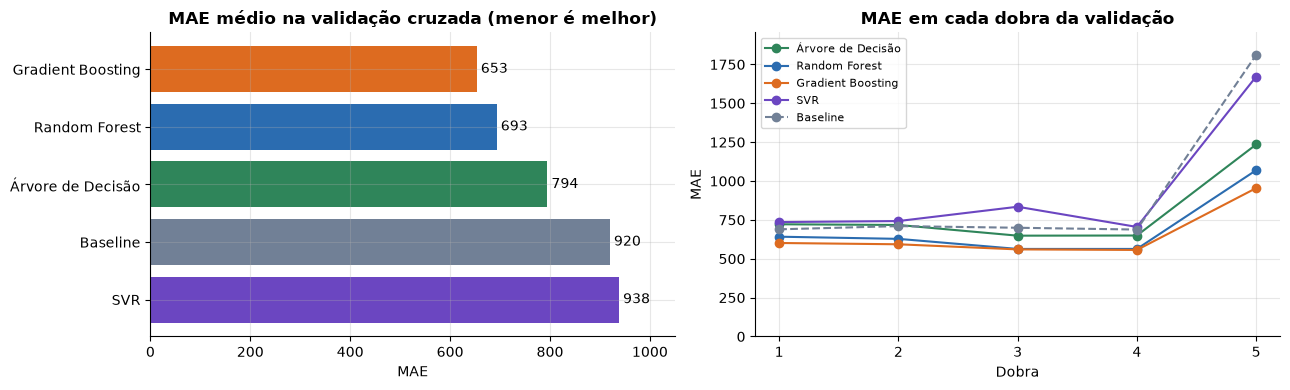

In [43]:
MELHOR = COMPARACAO_CV.index[0]
print('Modelo escolhido pela validação cruzada:', MELHOR)
print('Parâmetros:', COMPARACAO_CV.loc[MELHOR, 'melhores parâmetros'])
mae_por_dobra = pd.DataFrame({n: -pd.DataFrame(b.cv_results_).loc[b.best_index_,
                              [f'split{i}_test_MAE' for i in range(5)]].to_numpy(dtype=float) for n, b in BUSCAS.items()},
                             index=[f'dobra {i}' for i in range(1, 6)])
mae_por_dobra['Baseline'] = base_cv.MAE.to_numpy()
display(mae_por_dobra.round(0))

COR_MODELO = {'Gradient Boosting': LARANJA, 'Random Forest': AZUL, 'Árvore de Decisão': VERDE, 'SVR': ROXO, 'Baseline': CINZA}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
media = COMPARACAO_CV['MAE validação'][::-1]
curtos = [m.split(' (')[0] for m in media.index]
b = ax[0].barh(curtos, media.values, color=[COR_MODELO[m] for m in curtos])
ax[0].bar_label(b, labels=[br(v) for v in media.values], padding=3)
ax[0].set(title='MAE médio na validação cruzada (menor é melhor)', xlabel='MAE', xlim=(0, media.max() * 1.12))
for m in mae_por_dobra.columns:
    ax[1].plot(range(1, 6), mae_por_dobra[m], marker='o', color=COR_MODELO[m], label=m,
               ls='--' if m == 'Baseline' else '-')
ax[1].set(title='MAE em cada dobra da validação', xlabel='Dobra', xticks=range(1, 6), ylabel='MAE',
          ylim=(0, mae_por_dobra.max().max() * 1.08))
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Modelo escolhido: Gradient Boosting** (`learning_rate = 0,1`, `max_leaf_nodes = 63`). Ele tem o menor MAE em **todas** as 5 dobras, não só na média.

O gráfico da esquerda mostra a média das 5 dobras, e o da direita o erro em cada dobra. Os dois começam o eixo no zero.

Outros pontos da tabela por dobra:
- A árvore sozinha perde para o baseline nas dobras 1 e 2. Ela só ganha na média por causa das dobras 3, 4 e principalmente 5 (Natal).
- O SVR perde para o baseline em 4 das 5 dobras e só ganha na dobra 5, onde o baseline erra muito.
- Na dobra 5, todos os modelos erram bem mais. Natal e fim de ano têm dias atípicos, como 24 e 31 de dezembro.

Essa escolha fica registrada aqui, **antes** do teste.

## 16. Quais fatores influenciam as vendas

Três análises, todas feitas **no treino e na validação**, sem tocar no teste:

1. **Ablação, como no artigo-base:** tira grupos de variáveis e mede quanto o erro de validação piora.
2. **Importância por permutação:** embaralha uma coluna por vez numa amostra de 20 mil linhas da validação da dobra 5, três vezes, e mede quanto o MAE piora. Quanto mais piora, mais o modelo depende daquela coluna.
3. **Regras de uma árvore rasa:** uma árvore com 3 níveis mostra as primeiras divisões que o modelo faz, em linguagem de "se… então…".

MAE             RMSE  \
                                                       mean     std     mean   
completo (modelo escolhido)                          653.16  169.51   957.96   
sem promoção, feriado e dia da semana (teste do...  1511.14  231.64  2026.06   
sem histórico de vendas da loja                     1002.16  198.79  1531.11   

                                                              R2        
                                                       std  mean   std  
completo (modelo escolhido)                         229.54  0.91  0.02  
sem promoção, feriado e dia da semana (teste do...  226.64  0.57  0.12  
sem histórico de vendas da loja                     278.88  0.76  0.03

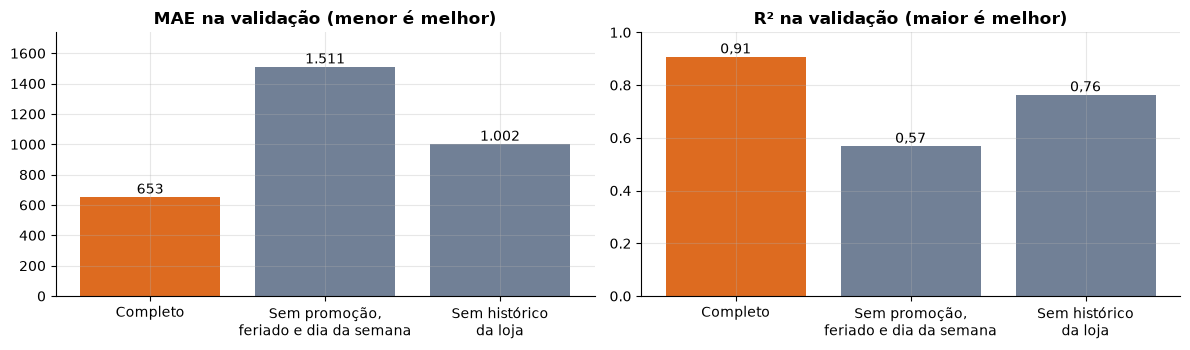

In [44]:
melhor_hgb = BUSCAS['Gradient Boosting'].best_estimator_.named_steps['modelo'].regressor
linha = pd.DataFrame(BUSCAS['Gradient Boosting'].cv_results_).loc[BUSCAS['Gradient Boosting'].best_index_]
completo = pd.DataFrame({m: [sinal * linha[f'split{i}_test_{m}'] for i in range(5)]
                         for m, sinal in [('MAE', -1), ('RMSE', -1), ('R2', 1)]}).agg(['mean', 'std']).unstack()
ablacao = pd.DataFrame({
    'completo (modelo escolhido)': completo,
    'sem promoção, feriado e dia da semana (teste do artigo)': cv_temporal(montar(clone(melhor_hgb), **{**CFG, 'ablacao': True})),
    'sem histórico de vendas da loja': cv_temporal(montar(clone(melhor_hgb), **{**CFG, 'historico': False})),
}).T
display(ablacao.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
rotulos = ['Completo', 'Sem promoção,\nferiado e dia da semana', 'Sem histórico\nda loja']
cores_abl = [LARANJA, CINZA, CINZA]
b0 = ax[0].bar(rotulos, ablacao[('MAE', 'mean')], color=cores_abl)
ax[0].bar_label(b0, labels=[br(v) for v in b0.datavalues]); ax[0].set(title='MAE na validação (menor é melhor)', ylim=(0, ablacao[('MAE', 'mean')].max() * 1.15))
b1 = ax[1].bar(rotulos, ablacao[('R2', 'mean')], color=cores_abl)
ax[1].bar_label(b1, labels=[br(v, 2) for v in b1.datavalues]); ax[1].set(title='R² na validação (maior é melhor)', ylim=(0, 1))
plt.tight_layout(); plt.show()

| Versão | MAE | R² |
|---|---|---|
| Completo | 653 | 0,91 |
| Sem promoção, feriado e dia da semana | 1.511 | 0,57 |
| Sem histórico de vendas da loja | 1.002 | 0,76 |

O gráfico mostra as três versões lado a lado, com o modelo completo em laranja.

Tirar promoção, feriado e dia da semana **mais que dobra o erro** e derruba o R² de 0,91 para 0,57. No artigo-base, a mesma retirada derrubou o R² de 0,884 para 0,607. A divisão e o modelo são outros, mas a direção e o tamanho da queda são parecidos.

Sem o histórico da loja, o R² cai para 0,76. O modelo ainda tem tipo de loja, sortimento e concorrência, mas isso não substitui saber quanto cada loja costuma vender.

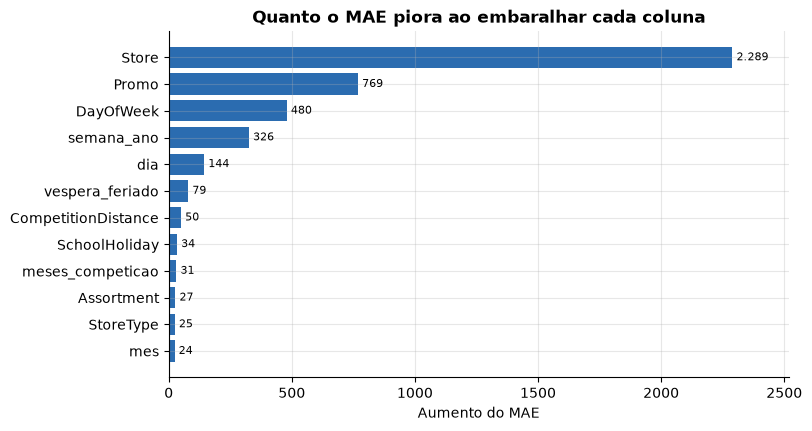

,aumento do MAE
Store,2289.2
Promo,768.7
DayOfWeek,479.5
semana_ano,325.7
dia,144.1
vespera_feriado,79.1
CompetitionDistance,50.2
SchoolHoliday,33.6
meses_competicao,31.0
Assortment,26.9


In [45]:
i_tr, i_va = DOBRAS[-1]
modelo_imp = clone(BUSCAS['Gradient Boosting'].best_estimator_).fit(X_treino.iloc[i_tr], y_treino.iloc[i_tr])
X_va = X_treino.iloc[i_va].sample(20_000, random_state=SEED)
y_va = y_treino.loc[X_va.index]
imp = permutation_importance(modelo_imp, X_va, y_va, scoring='neg_mean_absolute_error',
                             n_repeats=3, random_state=SEED)
IMPORTANCIA = pd.Series(imp.importances_mean, index=X_va.columns).sort_values(ascending=False)

top = IMPORTANCIA.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
b = ax.barh(top.index, top.values, color=AZUL)
ax.bar_label(b, labels=[br(v) for v in top.values], padding=3, fontsize=8)
ax.set(title='Quanto o MAE piora ao embaralhar cada coluna', xlabel='Aumento do MAE', xlim=(0, top.max() * 1.1))
plt.show()
display(IMPORTANCIA.round(1).to_frame('aumento do MAE'))

| Fator | Aumento do MAE ao embaralhar | Leitura |
|---|---|---|
| Qual é a loja (`Store`) | 2.289 | O maior fator. Embaralhar a loja destrói o histórico de vendas dela |
| Promoção do dia (`Promo`) | 769 | Segundo maior fator |
| Dia da semana | 480 | Segunda vende mais, sábado menos |
| Semana do ano e dia do mês | 326 e 144 | Época do ano. Pesam muito aqui porque esta validação é de fim de novembro a dezembro |
| Véspera de feriado | 79 | Pequeno, mas real |
| Concorrência, férias escolares, tipo e sortimento | entre 25 e 50 | Pouco peso |
| Promo2, `StateHoliday`, dia seguinte a feriado | menos de 4 | Quase nada |
| `Customers` | 0 | Não é usado. É mais uma prova de que não há vazamento |

`StateHoliday` pesa pouco porque quase todas as lojas fecham no feriado, e esses dias já saíram da base. O efeito do feriado aparece nas vésperas.

O dia seguinte a feriado quase não pesa aqui, apesar dos +10,7% da EDA. **Dedução nossa:** a validação de fim de novembro a dezembro tem poucos feriados, e o modelo pode estar captando esse efeito por `semana_ano` e `dia`. As duas colunas entraram juntas na seção 14, e o par melhorou a validação.

Esta importância vale para a dobra 5 (fim de ano). Em outra época do ano, o peso do calendário seria outro.

In [46]:
prep_arv = preprocessador(**CFG).fit(X_treino, y_treino)
arvore_rasa = DecisionTreeRegressor(max_depth=3, min_samples_leaf=1000, random_state=SEED)
arvore_rasa.fit(prep_arv.transform(X_treino), y_treino)
nomes_arv = list(prep_arv.get_feature_names_out())
print(export_text(arvore_rasa, feature_names=nomes_arv, decimals=2))

# hist_loja está em log: converte os cortes para venda média diária, para leitura
cortes = sorted({round(t, 2) for f, t in zip(arvore_rasa.tree_.feature, arvore_rasa.tree_.threshold)
                 if f >= 0 and nomes_arv[f] == 'hist_loja'})
print('Cortes de hist_loja em venda diária:', {float(c): round(float(np.exp(c))) for c in cortes})

|--- hist_loja <= 8.94
|   |--- hist_promo_vs_loja <= -0.03
|   |   |--- hist_loja <= 8.62
|   |   |   |--- value: [3959.43]
|   |   |--- hist_loja >  8.62
|   |   |   |--- value: [5755.63]
|   |--- hist_promo_vs_loja >  -0.03
|   |   |--- hist_loja <= 8.64
|   |   |   |--- value: [5807.39]
|   |   |--- hist_loja >  8.64
|   |   |   |--- value: [8120.01]
|--- hist_loja >  8.94
|   |--- hist_loja <= 9.37
|   |   |--- hist_promo_vs_loja <= -0.05
|   |   |   |--- value: [7909.12]
|   |   |--- hist_promo_vs_loja >  -0.05
|   |   |   |--- value: [10906.12]
|   |--- hist_loja >  9.37
|   |   |--- hist_loja <= 9.67
|   |   |   |--- value: [13704.64]
|   |   |--- hist_loja >  9.67
|   |   |   |--- value: [18881.05]

Cortes de hist_loja em venda diária: {8.62: 5541, 8.64: 5653, 8.94: 7631, 9.37: 11731, 9.67: 15835}


A árvore rasa só usa duas informações nas três primeiras divisões: o **nível de venda da loja** (`hist_loja`, em log) e **se o dia tem promoção** (`hist_promo_vs_loja`, que fica negativo nos dias sem promoção). Convertendo os cortes:

- A primeira pergunta é se a loja vende em média até cerca de **7.600 por dia**.
- Depois vem a promoção: nas lojas com média entre cerca de 5.500 e 7.600 por dia, um dia sem promoção prevê cerca de **5.756**, e um dia com promoção cerca de **8.120**.
- Nas lojas acima de 11.700 por dia, a árvore só separa por porte, até chegar à folha das maiores (cerca de 18.900).

Em linguagem simples, **primeiro importa qual é a loja, depois se tem promoção**. Isso bate com a importância por permutação e com a ablação.

## 17. Avaliação final no teste (uso único)

Até aqui o teste (janeiro a julho de 2015) não foi usado em nada: nem na EDA, nem na imputação, nem no K-means, nem na escolha de variáveis, hiperparâmetros ou modelo. Agora cada modelo, já re-treinado em 2013–2014 com os parâmetros escolhidos na seção 15, faz **uma** previsão do teste.

,MAE,RMSE,R2,RMSPE
modelo,,,,
Gradient Boosting,687.51,992.99,0.89,0.15
Random Forest,696.61,1022.29,0.89,0.15
Árvore de Decisão,767.35,1107.81,0.87,0.16
Baseline (média loja x dia x Promo),784.99,1163.20,0.85,0.17
SVR,921.27,1379.94,0.79,0.21


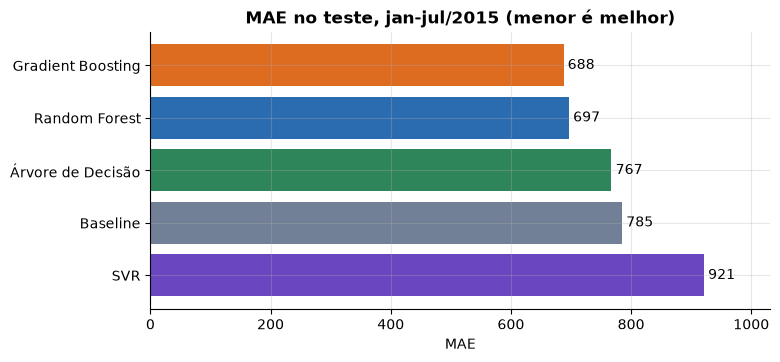

Gradient Boosting: MAE 12.4% menor que o do baseline no teste


Previsão do modelo escolhido idêntica com Customers = 0: True


In [47]:
# ÚNICO uso do teste: modelos já escolhidos e re-treinados no treino inteiro (2013-2014)
resultado, PREV = [], {}
PREV['Baseline'] = media_loja_dia_promo(treino, teste)
resultado.append({'modelo': 'Baseline (média loja x dia x Promo)', **metricas(y_teste, PREV['Baseline'])})
for nome, busca in BUSCAS.items():
    PREV[nome] = busca.best_estimator_.predict(X_teste)
    resultado.append({'modelo': nome, **metricas(y_teste, PREV[nome])})
RESULTADO_TESTE = pd.DataFrame(resultado).set_index('modelo').sort_values('MAE')
display(RESULTADO_TESTE.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
mae_teste = RESULTADO_TESTE.MAE[::-1]
curtos = [m.split(' (')[0] for m in mae_teste.index]
b = ax.barh(curtos, mae_teste.values, color=[COR_MODELO[m] for m in curtos])
ax.bar_label(b, labels=[br(v) for v in mae_teste.values], padding=3)
ax.set(title='MAE no teste, jan-jul/2015 (menor é melhor)', xlabel='MAE', xlim=(0, mae_teste.max() * 1.12))
plt.show()
mae_melhor, mae_base = RESULTADO_TESTE.MAE[MELHOR], RESULTADO_TESTE.MAE[[m for m in RESULTADO_TESTE.index if m.startswith('Baseline')][0]]
print(f'{MELHOR}: MAE {1 - mae_melhor / mae_base:.1%} menor que o do baseline no teste')
print('Previsão do modelo escolhido idêntica com Customers = 0:',
      np.allclose(PREV[MELHOR], BUSCAS[MELHOR].best_estimator_.predict(X_teste.assign(Customers=0))))

| Modelo | MAE | RMSE | R² | RMSPE |
|---|---|---|---|---|
| **Gradient Boosting** | **688** | **993** | **0,89** | **0,15** |
| Random Forest | 697 | 1.022 | 0,89 | 0,15 |
| Árvore de Decisão | 767 | 1.108 | 0,87 | 0,16 |
| Baseline | 785 | 1.163 | 0,85 | 0,17 |
| SVR | 921 | 1.380 | 0,79 | 0,21 |

O gráfico de barras usa as mesmas cores da seção 15, com o baseline em cinza.

A ordem dos modelos no teste é a **mesma** da validação, e o MAE do Gradient Boosting no teste (688) fica perto do da validação (653). Isso mostra que a validação cruzada temporal estimou bem o desempenho no futuro.

O Gradient Boosting erra, em média, **688 por loja por dia**, 12,4% menos que o baseline (785). O Random Forest fica muito perto (697). O R² de 0,89 é da mesma ordem do 0,884 do artigo-base, mas com outro período de teste, então não dá para dizer que um é melhor que o outro.

O SVR ficou **abaixo do baseline** também no teste, o que confirma o resultado da validação.

A última linha repete, agora no teste, a prova de que zerar `Customers` não muda nenhuma previsão.

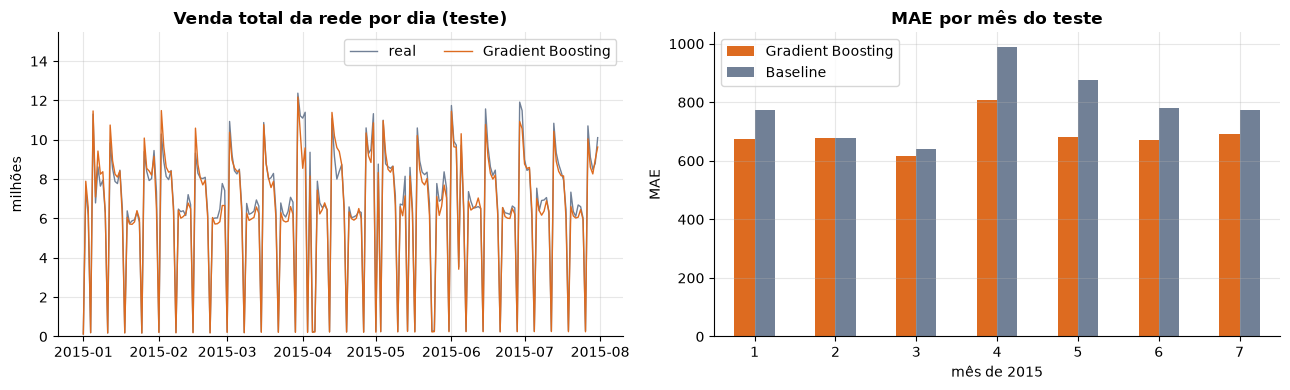

mes,1,2,3,4,5,6,7
Gradient Boosting,674.0,678.0,617.0,808.0,682.0,670.0,690.0
Baseline,774.0,679.0,639.0,989.0,877.0,781.0,773.0


,Gradient Boosting,Baseline,venda média,MAE em % da venda média
perfil,,,,
A - Dependentes de promoção,580.0,649.0,6168.0,9.4
B - Movimentadas de ticket baixo,790.0,934.0,8502.0,9.3
C - Ticket alto e pouco movimento,711.0,799.0,6834.0,10.4


In [48]:
aval = teste[['Date', 'mes', 'Sales']].assign(previsto=PREV[MELHOR], baseline=PREV['Baseline'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
diario = aval.groupby('Date')[['Sales', 'previsto']].sum() / 1e6
ax[0].plot(diario.index, diario.Sales, color=CINZA, lw=1, label='real')
ax[0].plot(diario.index, diario.previsto, color=LARANJA, lw=1, label=MELHOR)
ax[0].set(title='Venda total da rede por dia (teste)', ylabel='milhões', ylim=(0, diario.max().max() * 1.25)); ax[0].legend(ncol=2, loc='upper right')
erro_mes = pd.DataFrame({MELHOR: (aval.Sales - aval.previsto).abs().groupby(aval.mes).mean(),
                         'Baseline': (aval.Sales - aval.baseline).abs().groupby(aval.mes).mean()})
erro_mes.plot.bar(ax=ax[1], color=[LARANJA, CINZA], rot=0)
ax[1].set(title='MAE por mês do teste', xlabel='mês de 2015', ylabel='MAE')
plt.tight_layout(); plt.show()
display(erro_mes.round(0).T)

# Onde o modelo erra mais: MAE por grupo do K-means (grupos da seção 12, aprendidos no treino)
grupo_teste = teste.Store.map(perfil.grupo)
por_perfil = pd.DataFrame({MELHOR: (aval.Sales - aval.previsto).abs().groupby(grupo_teste).mean(),
                           'Baseline': (aval.Sales - aval.baseline).abs().groupby(grupo_teste).mean(),
                           'venda média': aval.Sales.groupby(grupo_teste).mean()}).rename(index=NOMES).rename_axis('perfil').round(0)
por_perfil['MAE em % da venda média'] = (por_perfil[MELHOR] / por_perfil['venda média'] * 100).round(1)
display(por_perfil)

No gráfico da esquerda, o modelo acompanha o sobe e desce semanal da rede: o domingo fica perto de zero porque quase todas as lojas fecham, e os picos aparecem nos dias de promoção. Nos picos mais altos, a previsão fica um pouco abaixo do real.

O Gradient Boosting erra menos que o baseline em todos os meses, com empate técnico em fevereiro (678 contra 679). O maior erro dos dois é em **abril**, mês da Páscoa em 2015. As maiores vantagens sobre o baseline são em maio (682 contra 877) e abril (808 contra 989).

Por perfil do K-means, o erro absoluto é maior no perfil B (movimentadas), mas essas lojas também vendem mais. Em proporção da venda média, os perfis A e B ficam perto de 9,3% a 9,4%, e o perfil C (ticket alto e pouco movimento) em 10,4%. É o perfil mais difícil de prever, então é onde a previsão merece mais margem de segurança no estoque.

## 18. Conclusão

**Pergunta: quais fatores influenciam a quantidade de vendas da Rossmann?**

| Ordem | Fator | Evidência |
|---|---|---|
| 1 | **Qual é a loja** (porte e histórico) | Sozinha explica 59,8% da variação (EDA). É o maior fator na importância por permutação, e sem ela o R² da validação cai de 0,91 para 0,76 |
| 2 | **Promoção do dia** | +39% em média. O efeito é maior na segunda (+56%) que na sexta (+22%) e varia por perfil de loja (+56% no perfil A, cerca de +32% nos outros) |
| 3 | **Dia da semana** | Segunda é o dia mais forte, sábado o mais fraco |
| 4 | **Época do ano** | Dezembro vende 27% acima dos outros meses. Semana do ano e dia do mês pesam no modelo |
| 5 | **Vizinhança de feriado** | Véspera +5,9% e dia seguinte +10,7%. O par entrou no modelo porque melhorou a validação |
| — | Pouco peso | Distância do concorrente, Promo2, férias escolares, tipo de loja e sortimento |

Juntos, promoção, feriado e dia da semana respondem por boa parte do acerto: sem eles, o R² cai de 0,91 para 0,57, um resultado parecido com o do artigo-base (de 0,884 para 0,607).

**Modelos**

| Pressuposto | Resultado |
|---|---|
| Árvores: a venda muda em degraus e os fatores se combinam | **Confirmado.** Os três modelos de árvore batem o baseline, e o Gradient Boosting é o melhor no teste (MAE 688, R² 0,89) |
| Random Forest: a média de muitas árvores erra menos que uma árvore só | **Confirmado.** MAE de 697 contra 767 da árvore sozinha |
| Gradient Boosting: o erro que sobra ainda tem padrão | **Confirmado.** É o melhor modelo nas 5 dobras e no teste |
| SVR: a venda varia de forma suave | **Não confirmado.** Ficou abaixo do baseline. A venda depende de combinações como loja × promoção × dia, que as árvores capturam melhor |
| K-means: existem perfis de loja não rotulados | **Confirmado, com ressalva.** Os 3 perfis se repetem de um ano para o outro (ARI 0,82), e o perfil formado em 2013 continua reagindo mais à promoção em 2014. A silhueta de 0,29 mostra fronteiras difusas, e o grupo não melhorou a previsão, porque o histórico da loja já carrega essa informação |

**O que o K-means entrega para o negócio**

| Perfil | Lojas | Estratégia sugerida |
|---|---|---|
| A — Dependentes de promoção | 399 | Concentrar campanhas aqui (+56% por promoção) e reforçar estoque e equipe nos dias de promoção |
| B — Movimentadas de ticket baixo | 326 | Dar conta do fluxo (caixas e reposição) e aumentar o gasto por cliente |
| C — Ticket alto e pouco movimento | 390 | Manter o sortimento amplo, atrair mais clientes e reforçar o sábado |

As estratégias são sugestões nossas a partir dos perfis. Para confirmar o ganho, a rede teria que testar, por exemplo, mais promoções no perfil A e comparar com o resto.

**Limitações**
- O teste vai de janeiro a julho e não tem dezembro, o mês mais difícil (veja a dobra 5).
- 180 lojas não têm dados no 2º semestre de 2014.
- O SVR treinou com 6 mil linhas, por causa do custo. Com mais linhas ele poderia melhorar, mas ficou longe dos modelos de árvore.
- As grades de hiperparâmetros são pequenas, e o melhor Gradient Boosting ficou na borda da grade.
- Os perfis do K-means têm fronteiras difusas (silhueta de 0,29). São tendências, não caixas fechadas.
- As ações sugeridas para cada perfil são hipóteses. Só a reação do perfil A à promoção foi conferida nos dados.
- Importância de variável mostra associação, não causa. O caso da Promo2, que aparece em lojas que já vendiam menos, mostra o cuidado necessário.

**Em relação ao projeto 1:** o notebook foi executado do início ao fim com as saídas salvas, toda escolha foi feita por validação cruzada no treino e registrada antes do teste, e tudo o que aprende com os dados ficou dentro do pipeline.

## 19. Especificações técnicas

In [49]:
import sys, platform
print('Python', sys.version.split()[0], '|', platform.system(), '|', os.cpu_count(), 'núcleos')
for m in [pd, np, sklearn, plt.matplotlib]:
    print(f'{m.__name__:12s}', m.__version__)
print('SEED =', SEED)
print(f'Tempo total de execução: {(time.time() - INICIO) / 60:.1f} min')

Python 3.13.16 | Linux | 2 núcleos
pandas       3.0.5
numpy        2.5.3
sklearn      1.9.1
matplotlib   3.11.2
SEED = 42
Tempo total de execução: 22.8 min


Para reproduzir: rodar do início ao fim (*Ambiente de execução → Executar tudo* no Colab). Toda aleatoriedade usa `SEED = 42`, então os números se repetem a cada execução na mesma versão das bibliotecas.

Bibliotecas: `pandas`, `numpy`, `scikit-learn` e `matplotlib`, todas já instaladas no Colab.